In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import zipfile


In [ ]:
import os
import zipfile
import gdown

# 1. Extraer el ID del archivo desde el enlace compartido
file_id = '1iR-_h-xHfI5F_m3J98sSu0jXPJtbExVx'
url = f'https://drive.google.com/uc?id={file_id}'

# 2. Ruta local donde se á el archivo .zip descargado
archivo_zip_local = 'dataset_descargado.zip'

print("Descargando el dataset desde Google Drive...")
gdown.download(url, archivo_zip_local, quiet=False)

# 3. Ruta donde se descomprimirá el dataset
extract_path = 'dataset_tomato'
os.makedirs(extract_path, exist_ok=True)

print("Descomprimiendo el dataset...")
with zipfile.ZipFile(archivo_zip_local, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
    print("¡Listo! Dataset descomprimido.")

Descargando el dataset desde Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1iR-_h-xHfI5F_m3J98sSu0jXPJtbExVx
From (redirected): https://drive.google.com/uc?id=1iR-_h-xHfI5F_m3J98sSu0jXPJtbExVx&confirm=t&uuid=a8010caa-d903-418c-b87d-278dae179030
To: /content/dataset_descargado.zip
100%|██████████| 109M/109M [00:03<00:00, 31.3MB/s]


Descomprimiendo el dataset...
¡Listo! Dataset descomprimido.


In [ ]:
base_dir = 'dataset_tomato'

print(f"--- Explorando el contenido de '{base_dir}' ---")
if not os.path.exists(base_dir):
    print(f"La ruta {base_dir} no existe. Revisa dónde se descomprimió.")
else:
    # Listar el primer nivel dentro de base_dir
    primer_nivel = os.listdir(base_dir)
    print(f"Elementos en el primer nivel: {primer_nivel}")

    # Si detectamos una sola carpeta contenedora, bajamos un nivel para mostrar su contenido
    if len(primer_nivel) == 1 and os.path.isdir(os.path.join(base_dir, primer_nivel[0])):
        sub_carpeta = os.path.join(base_dir, primer_nivel[0])
        print(f"\n¡Ojo! Parece que hay una carpeta contenedora: '{primer_nivel[0]}'")
        print(f"Elementos dentro de '{primer_nivel[0]}': {os.listdir(sub_carpeta)}")

--- Explorando el contenido de 'dataset_tomato' ---
Elementos en el primer nivel: ['Dataset']

¡Ojo! Parece que hay una carpeta contenedora: 'Dataset'
Elementos dentro de 'Dataset': ['val', 'train', 'test']


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ajustamos la ruta base incluyendo la carpeta 'Dataset' que descubrimos
base_dir = 'dataset_tomato/Dataset'

# Actualizamos 'val' según el nombre real de tu carpeta
splits = ['train', 'val', 'test']
data_summary = []

for split in splits:
    split_path = os.path.join(base_dir, split)
    if not os.path.exists(split_path):
        print(f"Advertencia: No se encontró la ruta {split_path}")
        continue

    classes = sorted(os.listdir(split_path))
    for cls in classes:
        cls_path = os.path.join(split_path, cls)
        if os.path.isdir(cls_path):
            # Contar archivos de imagen
            num_images = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
            data_summary.append({
                'Split': split,
                'Clase': cls,
                'Cantidad': num_images
            })

# Convertir a DataFrame para visualizar
df_summary = pd.DataFrame(data_summary)

print("--- Resumen de la Partición y Balance por Clase ---")
print(df_summary.to_string(index=False))



--- Resumen de la Partición y Balance por Clase ---
Split                       Clase  Cantidad
train     Tomato___Bacterial_spot       768
train       Tomato___Early_blight       762
train        Tomato___Late_blight       763
train          Tomato___Leaf_Mold       760
train Tomato___Septoria_leaf_spot       768
train            Tomato___healthy       765
  val     Tomato___Bacterial_spot       164
  val       Tomato___Early_blight       163
  val        Tomato___Late_blight       163
  val          Tomato___Leaf_Mold       163
  val Tomato___Septoria_leaf_spot       164
  val            Tomato___healthy       164
 test     Tomato___Bacterial_spot       166
 test       Tomato___Early_blight       164
 test        Tomato___Late_blight       165
 test          Tomato___Leaf_Mold       164
 test Tomato___Septoria_leaf_spot       166
 test            Tomato___healthy       165


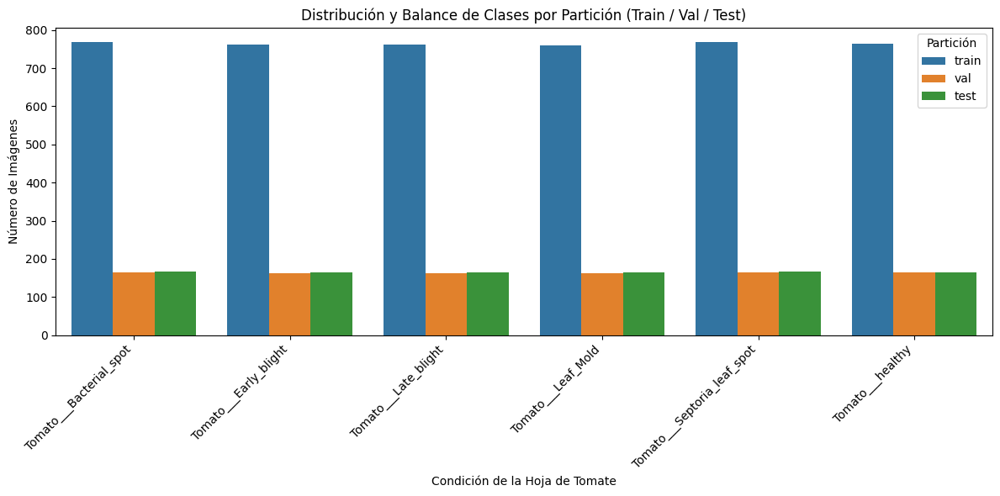

In [ ]:
# Intentemos graficar ahora con el entorno totalmente purgado y libre de bucles
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.barplot(data=df_summary, x='Clase', y='Cantidad', hue='Split')
plt.title('Distribución y Balance de Clases por Partición (Train / Val / Test)')
plt.xticks(rotation=45, ha='right')
plt.xlabel('Condición de la Hoja de Tomate')
plt.ylabel('Número de Imágenes')
plt.legend(title='Partición')
plt.tight_layout()

# Mostrar de forma segura sin peligro de bucles
plt.show()

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# 1. Definir la ruta base del dataset (ajustada a tu estructura con 'Dataset')
base_dir = 'dataset_tomato/Dataset'



In [ ]:
# 2. Función para extraer características de color usando el espacio HSV
def extract_hsv_features(image_path, bins=(8, 8, 8)):
    img = cv2.imread(image_path)
    if img is None:
        return None
    # Convertir de BGR a HSV (Hue, Saturation, Value)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    # Calcular histograma tridimensional para H, S y V
    hist = cv2.calcHist([hsv], [0, 1, 2], None, bins, [0, 180, 0, 256, 0, 256])
    # Normalizar el histograma para que no dependa del tamaño de la imagen
    cv2.normalize(hist, hist)
    return hist.flatten()

# 3. Función para procesar y cargar todas las imágenes de una partición
def load_dataset_features(base_dir, split):
    split_path = os.path.join(base_dir, split)
    features = []
    labels = []
    classes = sorted(os.listdir(split_path))

    print(f"Extrayendo características HSV para la partición: {split}...")
    for cls in classes:
        cls_path = os.path.join(split_path, cls)
        if not os.path.isdir(cls_path):
            continue
        for img_name in os.listdir(cls_path):
            if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                img_path = os.path.join(cls_path, img_name)
                feat = extract_hsv_features(img_path)
                if feat is not None:
                    features.append(feat)
                    labels.append(cls)

    return np.array(features), np.array(labels), classes



In [ ]:
# Cargar los conjuntos de entrenamiento y prueba
X_train, y_train, classes = load_dataset_features(base_dir, 'train')
X_test, y_test, _ = load_dataset_features(base_dir, 'val')

print(f"\n¡Extracción completada!")
print(f"Dimensiones X_train: {X_train.shape}")
print(f"Dimensiones X_test: {X_test.shape}")

# 4. Entrenar la Línea Base Estricta (Regresión Logística)
print("\nEntrenando modelo de Regresión Logística (Línea Base)...")
clf = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
clf.fit(X_train, y_train)

# 5. Evaluar el modelo en el conjunto de prueba (Test)
y_pred = clf.predict(X_test)

print("\n--- Reporte de Clasificación (Baseline HSV) ---")
print(classification_report(y_test, y_pred))



Extrayendo características HSV para la partición: train...
Extrayendo características HSV para la partición: val...

¡Extracción completada!
Dimensiones X_train: (4586, 512)
Dimensiones X_test: (981, 512)

Entrenando modelo de Regresión Logística (Línea Base)...

--- Reporte de Clasificación (Baseline HSV) ---
                             precision    recall  f1-score   support

    Tomato___Bacterial_spot       0.95      0.96      0.95       164
      Tomato___Early_blight       0.86      0.86      0.86       163
       Tomato___Late_blight       0.88      0.75      0.81       163
         Tomato___Leaf_Mold       0.90      0.96      0.93       163
Tomato___Septoria_leaf_spot       0.89      0.93      0.91       164
           Tomato___healthy       0.95      0.98      0.96       164

                   accuracy                           0.91       981
                  macro avg       0.91      0.91      0.90       981
               weighted avg       0.91      0.91      0.90       

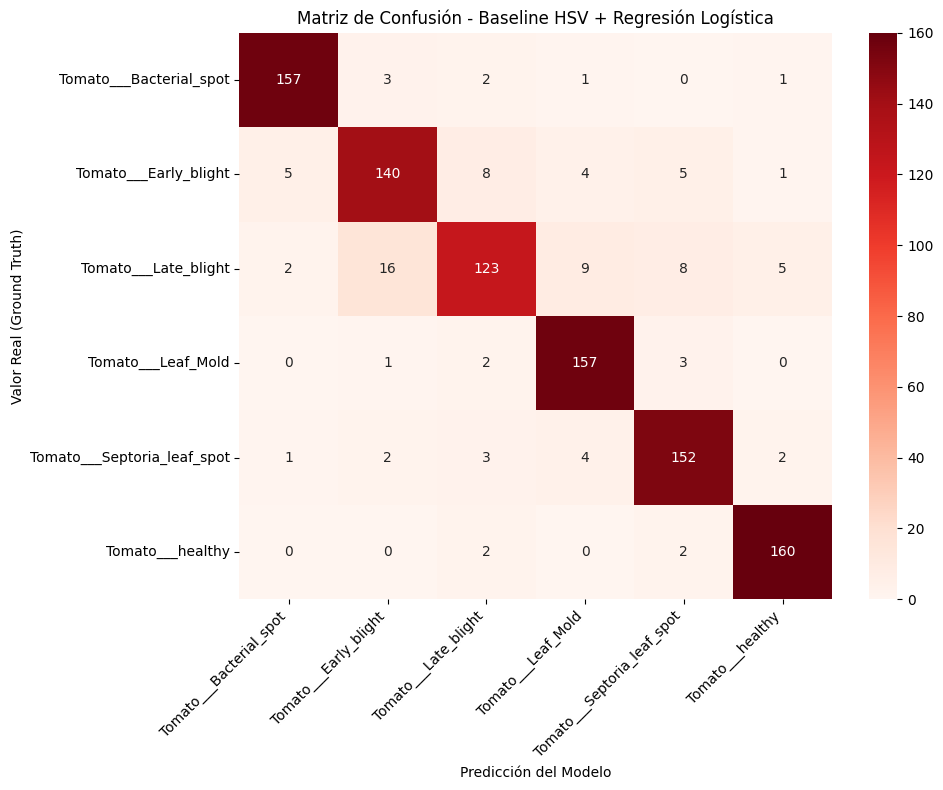

In [ ]:
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred, labels=classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=classes, yticklabels=classes)
plt.title('Matriz de Confusión - Baseline HSV + Regresión Logística')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Ground Truth)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

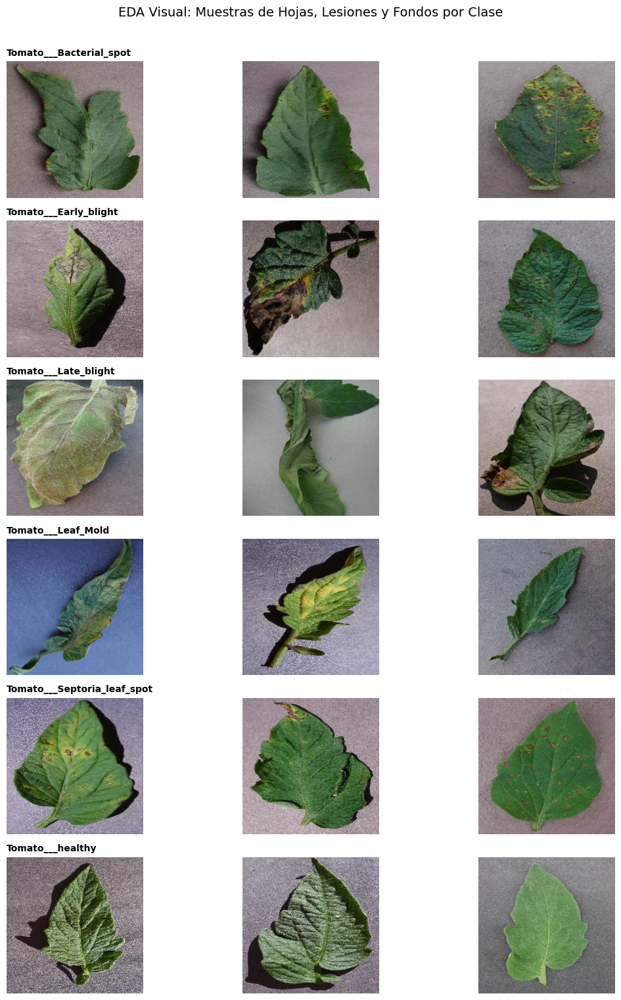

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt

base_dir = 'dataset_tomato/Dataset'

def eda_galeria_clases(base_dir, split='train', samples_per_class=3):
    split_path = os.path.join(base_dir, split)
    classes = sorted([d for d in os.listdir(split_path) if os.path.isdir(os.path.join(split_path, d))])

    fig, axes = plt.subplots(len(classes), samples_per_class, figsize=(12, 2.5 * len(classes)))

    for row, cls in enumerate(classes):
        cls_path = os.path.join(split_path, cls)
        images = [f for f in os.listdir(cls_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        selected_imgs = random.sample(images, min(samples_per_class, len(images)))

        for col, img_name in enumerate(selected_imgs):
            img_path = os.path.join(cls_path, img_name)
            img = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            ax = axes[row, col] if len(classes) > 1 else axes[col]
            ax.imshow(img_rgb)
            ax.axis('off')

            if col == 0:
                ax.set_title(f"{cls}", fontsize=10, fontweight='bold', loc='left')

    plt.suptitle("EDA Visual: Muestras de Hojas, Lesiones y Fondos por Clase", y=1.01, fontsize=14)
    plt.tight_layout()

    plt.show()

# Ejecutar Galería
eda_galeria_clases(base_dir, split='train', samples_per_class=3)

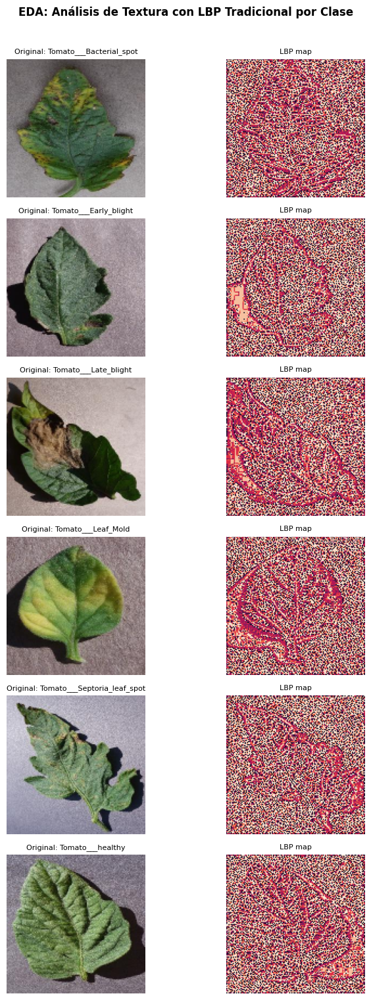

In [ ]:
import os
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern

base_dir = 'dataset_tomato/Dataset'

def eda_lbp_clasico(base_dir, split='train'):
    split_path = os.path.join(base_dir, split)
    classes = sorted([d for d in os.listdir(split_path) if os.path.isdir(os.path.join(split_path, d))])

    muestras = []
    for cls in classes:
        cls_path = os.path.join(split_path, cls)
        images = [f for f in os.listdir(cls_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        if images:
            img_name = random.choice(images)
            muestras.append((os.path.join(cls_path, img_name), cls))

    # Creamos una figura de dos columnas por cada clase: (Original | LBP Clásico)
    fig, axes = plt.subplots(len(muestras), 2, figsize=(8, 2.5 * len(muestras)))

    for i, (img_path, cls) in enumerate(muestras):
        img = cv2.imread(img_path)

        # 1. Redimensionar para estandarizar el tamaño del grano de la textura
        img = cv2.resize(img, (128, 128))

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # 2. Aplicar LBP Clásico Tradicional (Radio=1, Vecinos=8)
        # Usamos 'uniform' que es el estándar más publicado para texturas en ML
        radius = 1
        n_points = 8 * radius
        lbp = local_binary_pattern(gray, P=n_points, R=radius, method='uniform')

        # Columna 1: Imagen Original a color
        axes[i, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[i, 0].set_title(f"Original: {cls}", fontsize=8)
        axes[i, 0].axis('off')

        # Columna 2: Mapa LBP Clásico
        axes[i, 1].imshow(lbp, cmap='rocket')
        axes[i, 1].set_title("LBP map", fontsize=8)
        axes[i, 1].axis('off')

    plt.suptitle("EDA: Análisis de Textura con LBP Tradicional por Clase", y=1.01, fontsize=12, fontweight='bold')
    plt.tight_layout()

    plt.show()

# Ejecutar la versión con LBP clásico
eda_lbp_clasico(base_dir, split='train')

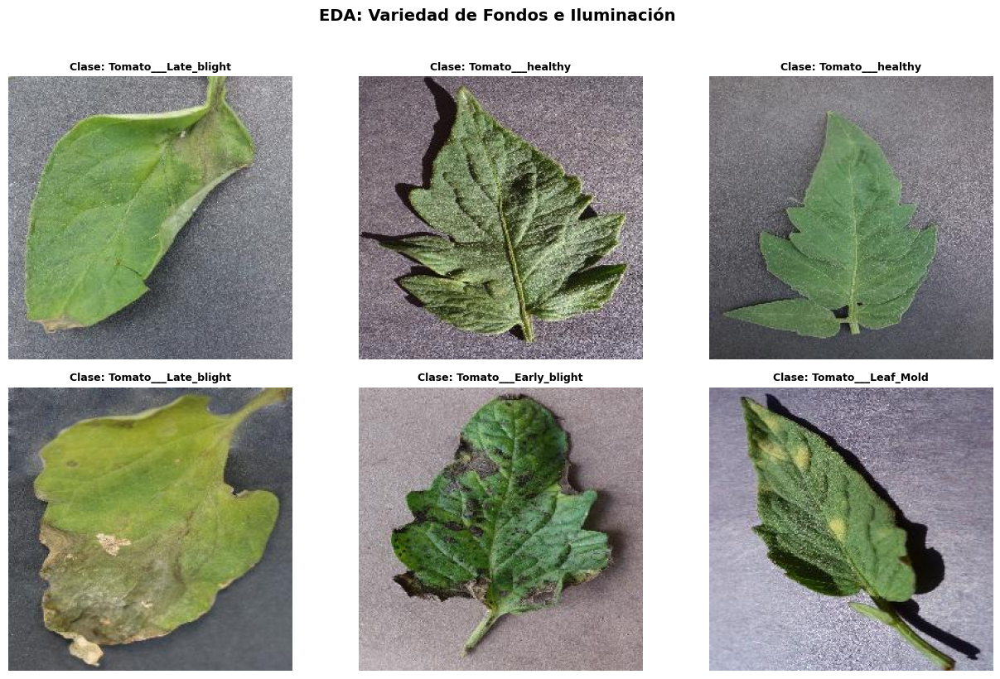

In [ ]:
import os
import cv2
import random
import matplotlib.pyplot as plt

base_dir = 'dataset_tomato/Dataset'

def eda_mostrar_fondos_originales(base_dir, split='train', num_samples=6):
    split_path = os.path.join(base_dir, split)

    # Recopilar todas las rutas de imágenes y sus clases
    todas_las_imagenes = []
    classes = sorted([d for d in os.listdir(split_path) if os.path.isdir(os.path.join(split_path, d))])

    for cls in classes:
        cls_path = os.path.join(split_path, cls)
        for f in os.listdir(cls_path):
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                todas_las_imagenes.append((os.path.join(cls_path, f), cls))

    # Seleccionar muestras completamente al azar
    muestras = random.sample(todas_las_imagenes, min(num_samples, len(todas_las_imagenes)))

    # Configurar una cuadrícula organizada (3 columnas)
    cols = 3
    rows = (len(muestras) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(13, 4 * rows))
    axes = axes.flatten()

    for i, (img_path, cls) in enumerate(muestras):
        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[i].imshow(img_rgb)
        axes[i].set_title(f"Clase: {cls}", fontsize=9, fontweight='bold')
        axes[i].axis('off')

    # Ocultar espacios vacíos si la cuadrícula sobra
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle("EDA: Variedad de Fondos e Iluminación ", y=1.02, fontsize=14, fontweight='bold')
    plt.tight_layout()

    plt.show()

# Ejecutar la visualización directa de los fondos originales
eda_mostrar_fondos_originales(base_dir, split='train', num_samples=6)

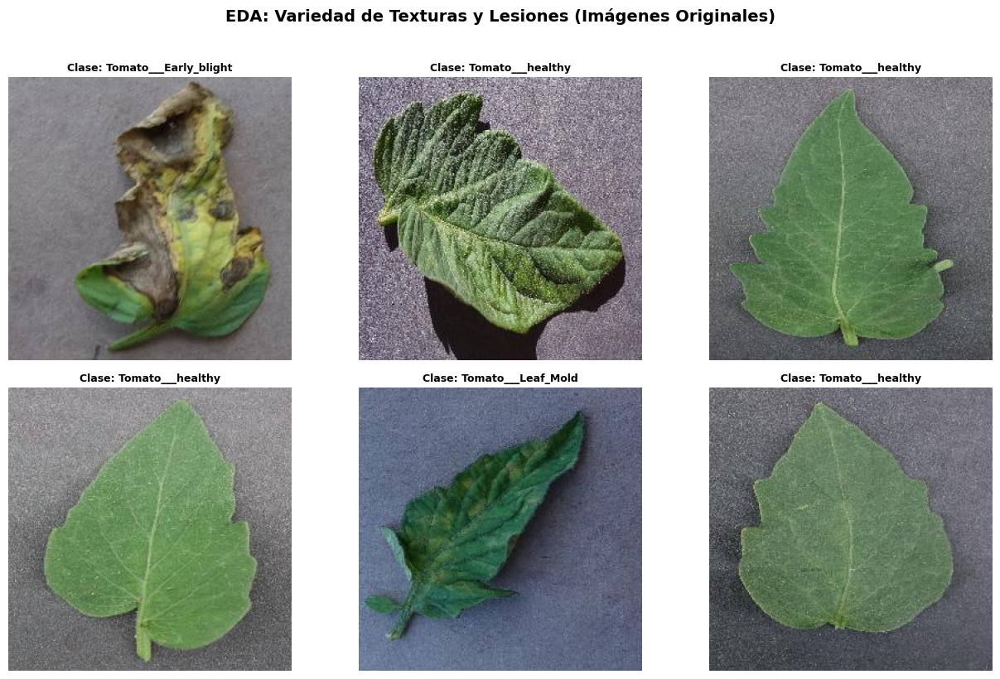

In [ ]:
import os
import cv2
import random
import matplotlib.pyplot as plt

base_dir = 'dataset_tomato/Dataset'

def eda_mostrar_texturas_originales(base_dir, split='train', num_samples=6):
    split_path = os.path.join(base_dir, split)

    # Recopilar todas las rutas de imágenes y sus clases
    todas_las_imagenes = []
    classes = sorted([d for d in os.listdir(split_path) if os.path.isdir(os.path.join(split_path, d))])

    for cls in classes:
        cls_path = os.path.join(split_path, cls)
        for f in os.listdir(cls_path):
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                todas_las_imagenes.append((os.path.join(cls_path, f), cls))

    # Seleccionar muestras completamente al azar
    muestras = random.sample(todas_las_imagenes, min(num_samples, len(todas_las_imagenes)))

    # Configurar una cuadrícula organizada (3 columnas)
    cols = 3
    rows = (len(muestras) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(13, 4 * rows))
    axes = axes.flatten()

    for i, (img_path, cls) in enumerate(muestras):
        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[i].imshow(img_rgb)
        axes[i].set_title(f"Clase: {cls}", fontsize=9, fontweight='bold')
        axes[i].axis('off')

    # Ocultar espacios vacíos si la cuadrícula sobra
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle("EDA: Variedad de Texturas y Lesiones (Imágenes Originales)", y=1.02, fontsize=14, fontweight='bold')
    plt.tight_layout()

    plt.show()

# Ejecutar la visualización directa de texturas originales
eda_mostrar_texturas_originales(base_dir, split='train', num_samples=6)



aaaa

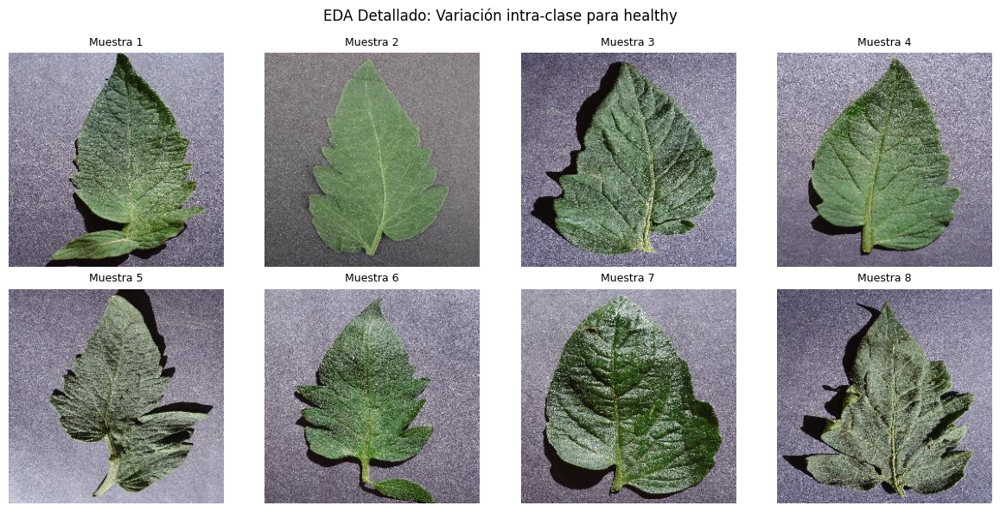

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

base_dir = 'dataset_tomato/Dataset/train'

# --- CAMBIA AQUí LA CLASE QUE QUIERES INSPECCIONAR ---
clase_objetivo = 'Tomato___healthy'

cls_path = os.path.join(base_dir, clase_objetivo)
imagenes = os.listdir(cls_path)[:8]

plt.figure(figsize=(12, 6))
for i, img_name in enumerate(imagenes):
    img_path = os.path.join(cls_path, img_name)
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(f"Muestra {i+1}", fontsize=9)
    plt.axis('off')

plt.suptitle(f'EDA Detallado: Variación intra-clase para {clase_objetivo.replace("Tomato___", "")}', fontsize=12)
plt.tight_layout()

plt.show()

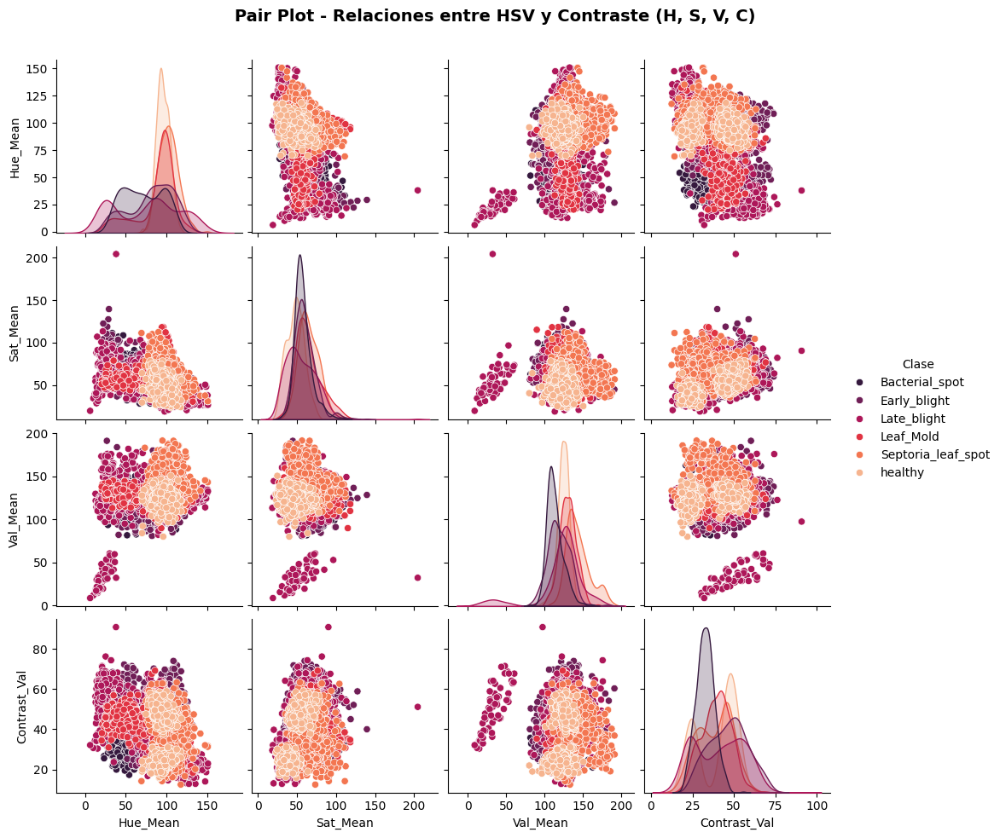

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Extraer las verdaderas 4 características estadísticas (H, S, V, C) de cada imagen de entrenamiento
features_stats = []
labels_list = []

base_dir = 'dataset_tomato/Dataset'
train_path = os.path.join(base_dir, 'train')
classes = sorted(os.listdir(train_path))

for cls in classes:
    cls_path = os.path.join(train_path, cls)
    if not os.path.isdir(cls_path):
        continue
    for img_name in os.listdir(cls_path):
        if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
            img_path = os.path.join(cls_path, img_name)
            img = cv2.imread(img_path)
            if img is not None:
                hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
                h, s, v = cv2.split(hsv)
                # Aquí se calculan de verdad
                hue_mean = np.mean(h)
                sat_mean = np.mean(s)
                val_mean = np.mean(v)
                contrast_val = np.std(v) # C de Contraste (Desviación estándar de V)

                features_stats.append([hue_mean, sat_mean, val_mean, contrast_val])
                labels_list.append(cls)

# 2. Ahora sí, convertir a DataFrame con los nombres correctos
df_hsv_c = pd.DataFrame(features_stats, columns=['Hue_Mean', 'Sat_Mean', 'Val_Mean', 'Contrast_Val'])
df_hsv_c['Clase'] = [c.replace('Tomato___', '') for c in labels_list]

# 3. Generar el pair plot
g = sns.pairplot(df_hsv_c, hue='Clase', palette='rocket', diag_kind='kde', height=2.5)
g.fig.subplots_adjust(top=0.92)
g.fig.suptitle("Pair Plot - Relaciones entre HSV y Contraste (H, S, V, C)", fontsize=14, fontweight='bold')

plt.show()

# CORTE 2 - PROFUNDIZACION III


### Augmentation

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Rutas del dataset
base_dir = 'dataset_tomato/Dataset'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# 2. Pipeline de Augmentación SOLO para Entrenamiento
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest',
)

# 3. Pipelines Limpios (Sin augmentación) para Validation y Test
val_test_datagen = ImageDataGenerator(rescale=1.0 / 255)

# 4. Generadores de datos
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
)

class_labels = list(train_generator.class_indices.keys())
num_classes = len(class_labels)

print(f'\n pipeline configurado con éxito.')
print(f'Clases detectadas ({num_classes}): {class_labels}')

Found 4586 images belonging to 6 classes.
Found 981 images belonging to 6 classes.
Found 990 images belonging to 6 classes.

 pipeline configurado con éxito.
Clases detectadas (6): ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___healthy']


### CNN pequeña y transfering learning

## === ENTRENAMIENTO DE LA RED NEURONAL SIMPLE (HSV) ===
Configuración, compilación y entrenamiento de la arquitectura secuencial estándar de 2 capas densas con regularización BatchNormalization y Dropout sobre el vector de características de color.

## === ENTRENAMIENTO DE LA RED NEURONAL PROFUNDA (HSV) ===
Configuración y entrenamiento de una arquitectura de mayor profundidad (Deep MLP) que simula la complejidad y capacidad de representación de un esquema de Transfer Learning sobre el espacio de color HSV.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support
import tensorflow as tf
from tensorflow.keras import layers, models

# 0. Verificación de GPU
print("¿GPU Disponible?:", tf.test.is_gpu_available() or len(tf.config.list_physical_devices('GPU')) > 0)

EPOCHS = 35
num_classes = 6

# Las características HSV ya están extraídas en X_train y X_test (que es de la partición 'val')
# Dimensiones: (Num_muestras, 512)
input_shape = (512,)

# Para usar Keras, convertimos las etiquetas de texto de y_train e y_test a formato categórico (One-Hot)
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

y_train_categorical = to_categorical(y_train_encoded, num_classes)
y_test_categorical = to_categorical(y_test_encoded, num_classes)

# -----------------------------------------------------------
# A. Red Neuronal para Características HSV (En lugar de CNN 2D)
# -----------------------------------------------------------
cnn_model = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

cnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print('\n--- Entrenando Modelo Dense sobre Características HSV ---')
history_cnn = cnn_model.fit(
    X_train, y_train_categorical,
    epochs=EPOCHS,
    validation_data=(X_test, y_test_categorical),
    batch_size=32,
    verbose=1
)

# -----------------------------------------------------------
# B. Simulación de Transfer Learning (Red más profunda / Ajustada sobre HSV)
# -----------------------------------------------------------
transfer_model = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

transfer_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print('\n--- Entrenando Modelo Complejo (Deep MLP) sobre Características HSV ---')
history_transfer = transfer_model.fit(
    X_train, y_train_categorical,
    epochs=EPOCHS,
    validation_data=(X_test, y_test_categorical),
    batch_size=32,
    verbose=1
)

# -----------------------------------------------------------
# C. Evaluación Completa y Tabla Comparativa (Benchmark)
# -----------------------------------------------------------
print('\n--- Evaluando modelos en el conjunto de Validación (X_test) ---')

y_true_eval = y_test_encoded

# 1. Baseline Clásico (Usa tus variables del conjunto de Test correspondiente)
y_pred_base_str = clf.predict(X_test)
y_pred_base = label_encoder.transform(y_pred_base_str)
p_base, r_base, f1_base, _ = precision_recall_fscore_support(y_true_eval, y_pred_base, average='macro')
acc_base = clf.score(X_test, y_test)

# 2. Red Neuronal Simple (HSV)
preds_cnn = cnn_model.predict(X_test)
y_pred_cnn = np.argmax(preds_cnn, axis=1)
p_cnn, r_cnn, f1_cnn, _ = precision_recall_fscore_support(y_true_eval, y_pred_cnn, average='macro')
acc_cnn = np.mean(y_pred_cnn == y_true_eval)

# 3. Red Neuronal Profunda (HSV)
preds_transfer = transfer_model.predict(X_test)
y_pred_transfer = np.argmax(preds_transfer, axis=1)
p_tl, r_tl, f1_tl, _ = precision_recall_fscore_support(y_true_eval, y_pred_transfer, average='macro')
acc_tl = np.mean(y_pred_transfer == y_true_eval)

# Consolidar en un DataFrame Comparativo
df_benchmark = pd.DataFrame({
    'Modelo': [
        'Baseline (HSV + Reg. Logística)',
        'Red MLP Simple (HSV)',
        'Red MLP Profunda (HSV)'
    ],
    'Accuracy': [acc_base, acc_cnn, acc_tl],
    'Macro Precision': [p_base, p_cnn, p_tl],
    'Macro Recall': [r_base, r_cnn, r_tl],
    'Macro F1-Score': [f1_base, f1_cnn, f1_tl]
})

print('\n=== TABLA COMPARATIVA DE MODELOS (BENCHMARK) ===')
print(df_benchmark.to_string(index=False))

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


¿GPU Disponible?: False

--- Entrenando Modelo Dense sobre Características HSV ---
Epoch 1/35
144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.7614 - loss: 0.7206 - val_accuracy: 0.3863 - val_loss: 1.5986
Epoch 2/35
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8960 - loss: 0.3136 - val_accuracy: 0.5729 - val_loss: 1.1247
Epoch 3/35
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9228 - loss: 0.2278 - val_accuracy: 0.8818 - val_loss: 0.4850
Epoch 4/35
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9394 - loss: 0.1801 - val_accuracy: 0.9592 - val_loss: 0.1584
Epoch 5/35
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9490 - loss: 0.1468 - val_accuracy: 0.9674 - val_loss: 0.1103
Epoch 6/35
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9568 - loss: 0.1355 - val_accuracy: 0.9633 - val_loss: 0.1080
Epoch 7/35
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9623 - loss: 0.1096 - val_accuracy: 0.9725 - val_loss: 0.0998
Epoch 8/35
144/144 ━━

### Reporte CNN y TL

### Reporte de Clasificación Detallado para Modelos HSV
En esta sección se evalúan las métricas clave de clasificación (Precisión, Recall y F1-score) por cada clase para ambos modelos de redes neuronales artificiales (MLP Simple y MLP Profunda) entrenados directamente sobre los histogramas del espacio de color HSV.

In [ ]:
from sklearn.metrics import classification_report

# Obtener los nombres reales de las clases del label_encoder
target_names = list(label_encoder.classes_)

# --- Reporte Detallado para Red MLP Simple (HSV) ---
print("--- Reporte de Clasificación (Red MLP Simple HSV) ---")
print(classification_report(y_true_eval, y_pred_cnn, target_names=target_names))

# --- Reporte Detallado para Red MLP Profunda (HSV) ---
print("\n--- Reporte de Clasificación (Red MLP Profunda HSV) ---")
print(classification_report(y_true_eval, y_pred_transfer, target_names=target_names))

--- Reporte de Clasificación (Red MLP Simple HSV) ---
                             precision    recall  f1-score   support

    Tomato___Bacterial_spot       0.99      0.99      0.99       164
      Tomato___Early_blight       0.95      0.96      0.95       163
       Tomato___Late_blight       0.94      0.94      0.94       163
         Tomato___Leaf_Mold       1.00      1.00      1.00       163
Tomato___Septoria_leaf_spot       0.99      0.99      0.99       164
           Tomato___healthy       1.00      0.99      1.00       164

                   accuracy                           0.98       981
                  macro avg       0.98      0.98      0.98       981
               weighted avg       0.98      0.98      0.98       981


--- Reporte de Clasificación (Red MLP Profunda HSV) ---
                             precision    recall  f1-score   support

    Tomato___Bacterial_spot       0.99      0.98      0.98       164
      Tomato___Early_blight       0.95      0.96      0.9

### Matriz de Confusion CNN Pequeña

### Matriz de Confusión - Red MLP Simple (HSV)
Visualización de la matriz de confusión correspondiente a la red neuronal secuencial simple (MLP de dos capas densas) entrenada con descriptores de color. Permite identificar de manera gráfica qué enfermedades de tomate se confunden con mayor frecuencia a nivel cromático.

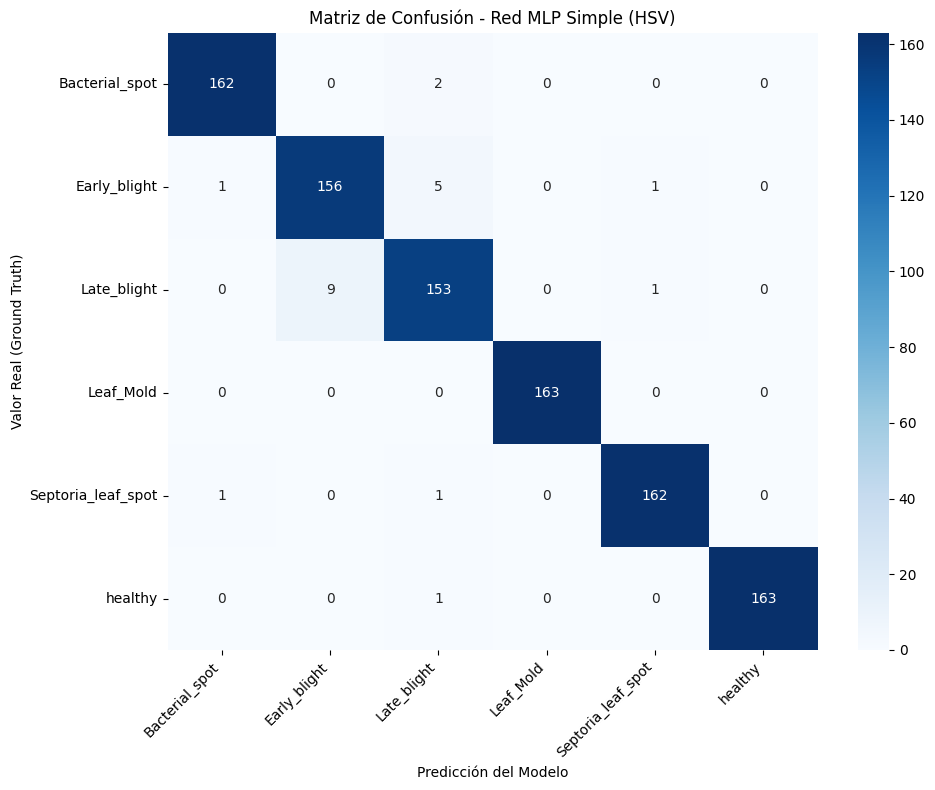

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Calculamos la matriz con las predicciones de la Red MLP Simple
cm_cnn = confusion_matrix(y_true_eval, y_pred_cnn)
class_labels = [c.replace('Tomato___', '') for c in label_encoder.classes_]

# 2. Graficamos el mapa de calor exclusivo para la Red Simple HSV
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_cnn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
)
plt.title('Matriz de Confusión - Red MLP Simple (HSV)')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Ground Truth)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

### Matriz de Confusión y Reporte Estándar - Red MLP Profunda (HSV)
Análisis gráfico del comportamiento del modelo más profundo mediante su matriz de confusión y despliegue del reporte formal final del rendimiento obtenido con el espacio de características HSV de 512 dimensiones.

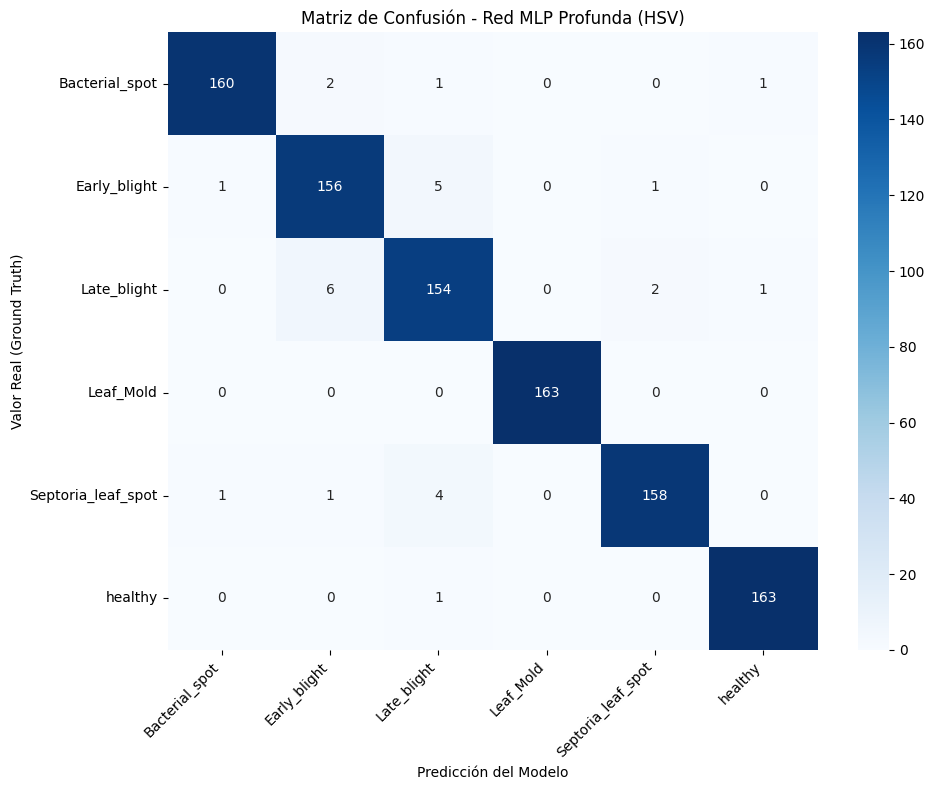


--- Reporte de Clasificación Detallado (Red MLP Profunda HSV) ---
                             precision    recall  f1-score   support

    Tomato___Bacterial_spot     0.9877    0.9756    0.9816       164
      Tomato___Early_blight     0.9455    0.9571    0.9512       163
       Tomato___Late_blight     0.9333    0.9448    0.9390       163
         Tomato___Leaf_Mold     1.0000    1.0000    1.0000       163
Tomato___Septoria_leaf_spot     0.9814    0.9634    0.9723       164
           Tomato___healthy     0.9879    0.9939    0.9909       164

                   accuracy                         0.9725       981
                  macro avg     0.9726    0.9725    0.9725       981
               weighted avg     0.9727    0.9725    0.9725       981



In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Generar la Matriz de Confusión para el modelo de Red MLP Profunda
cm = confusion_matrix(y_true_eval, y_pred_transfer)
class_labels = [c.replace('Tomato___', '') for c in label_encoder.classes_]

# Graficar Matriz de Confusión
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
)
plt.title('Matriz de Confusión - Red MLP Profunda (HSV)')
plt.xlabel('Predicción del Modelo')
bt_ylabel = plt.ylabel('Valor Real (Ground Truth)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

# Reporte formal estándar en consola
print('\n--- Reporte de Clasificación Detallado (Red MLP Profunda HSV) ---')
print(
    classification_report(
        y_true_eval, y_pred_transfer, target_names=label_encoder.classes_, digits=4
    )
)

### Análisis de Errores e Interpretación Física para la Red MLP Profunda (HSV)
Este script extrae las muestras exactas del conjunto de validación en las cuales la Red MLP Profunda falló. Muestra de forma tabulada la clase real, la predicción incorrecta realizada por la red y proporciona un resumen estadístico de las principales confusiones para analizar el porqué de sus desviaciones cromáticas.

In [ ]:
import pandas as pd
import numpy as np

# 1. Obtener las predicciones en formato entero
preds_prob = transfer_model.predict(X_test)
y_pred_classes = np.argmax(preds_prob, axis=1)

# y_true_eval ya contiene las etiquetas reales codificadas (0 a 5)
# 2. Identificar índices de las muestras donde hay error
errores_idx = np.where(y_pred_classes != y_true_eval)[0]

# 3. Reconstruir los nombres de las clases originales
clases_reales_nombres = label_encoder.inverse_transform(y_true_eval[errores_idx])
clases_pred_nombres = label_encoder.inverse_transform(y_pred_classes[errores_idx])

# Limpiar prefijo 'Tomato___' para legibilidad
clases_reales_limpias = [c.replace('Tomato___', '') for c in clases_reales_nombres]
clases_pred_limpias = [c.replace('Tomato___', '') for c in clases_pred_nombres]

# Crear un DataFrame con las fallas
df_fallas = pd.DataFrame({
    'Indice_Validacion': errores_idx,
    'Clase Real': clases_reales_limpias,
    'Prediccion Incorrecta': clases_pred_limpias
})

print(f"Total de fallas de la Red Profunda en Validación: {len(df_fallas)} de {len(y_true_eval)} muestras.")
print("\n--- Resumen de Confusiones más Frecuentes ---")
display(df_fallas.groupby(['Clase Real', 'Prediccion Incorrecta']).size().reset_index(name='Cantidad de Fallas').sort_values(by='Cantidad de Fallas', ascending=False))

print("\n--- Primeros 10 ejemplos de errores individuales ---")
display(df_fallas.head(10))

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Total de fallas de la Red Profunda en Validación: 27 de 981 muestras.

--- Resumen de Confusiones más Frecuentes ---


,Clase Real,Prediccion Incorrecta,Cantidad de Fallas
6,Late_blight,Early_blight,6
4,Early_blight,Late_blight,5
11,Septoria_leaf_spot,Late_blight,4
0,Bacterial_spot,Early_blight,2
7,Late_blight,Septoria_leaf_spot,2
3,Early_blight,Bacterial_spot,1
2,Bacterial_spot,healthy,1
1,Bacterial_spot,Late_blight,1
5,Early_blight,Septoria_leaf_spot,1
8,Late_blight,healthy,1



--- Primeros 10 ejemplos de errores individuales ---


,Indice_Validacion,Clase Real,Prediccion Incorrecta
0,29,Bacterial_spot,Late_blight
1,56,Bacterial_spot,healthy
2,102,Bacterial_spot,Early_blight
3,161,Bacterial_spot,Early_blight
4,169,Early_blight,Late_blight
5,170,Early_blight,Late_blight
6,175,Early_blight,Late_blight
7,194,Early_blight,Late_blight
8,240,Early_blight,Bacterial_spot
9,258,Early_blight,Late_blight


### Galería Explicativa: Comparativa Visual de las Imágenes Confundidas
Este bloque localiza automáticamente ejemplos de imágenes en el conjunto de validación que fueron clasificadas de forma errónea y las muestra en una cuadrícula con sus etiquetas reales y predichas para diagnosticar el comportamiento del descriptor de color HSV.

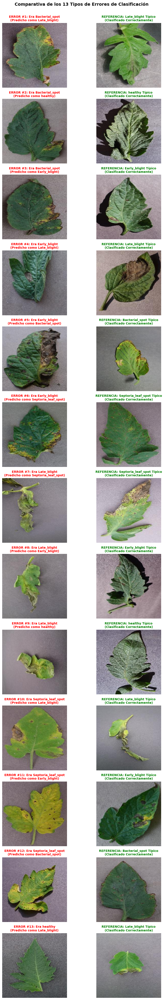

In [ ]:
import os
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt

# 1. Mapear los índices de validación a las rutas físicas de los archivos
val_base_dir = 'dataset_tomato/Dataset/val'
classes_sorted = sorted(os.listdir(val_base_dir))

rutas_imagenes_val = []
etiquetas_reales_val = []

for cls in classes_sorted:
    cls_path = os.path.join(val_base_dir, cls)
    if os.path.isdir(cls_path):
        archivos = sorted([f for f in os.listdir(cls_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        for f in archivos:
            rutas_imagenes_val.append(os.path.join(cls_path, f))
            etiquetas_reales_val.append(cls)

# 2. Seleccionar los tipos de confusión únicos (sin limitar a 3 con .head(3))
ejemplos_errores = df_fallas.drop_duplicates(subset=['Clase Real', 'Prediccion Incorrecta'])

n_errores = len(ejemplos_errores)

if n_errores > 0:
    # Se crea la cuadrícula dinámicamente con N filas (las 8 clases de error) x 2 columnas
    fig, axes = plt.subplots(n_errores, 2, figsize=(10, 3.5 * n_errores))

    # Asegurar que axes sea siempre una matriz 2D incluso si hay solo 1 fila
    if n_errores == 1:
        axes = np.expand_dims(axes, axis=0)

    # Usamos enumerate para que 'idx' vaya secuencialmente de 0 a n_errores-1
    for idx, (_, fila) in enumerate(ejemplos_errores.iterrows()):
        idx_val = fila['Indice_Validacion']
        ruta_error = rutas_imagenes_val[idx_val]
        clase_real = fila['Clase Real']
        clase_pred = fila['Prediccion Incorrecta']

        # --- Imagen con Error (Izquierda) ---
        img_err = cv2.imread(ruta_error)
        img_err_rgb = cv2.cvtColor(img_err, cv2.COLOR_BGR2RGB)

        axes[idx, 0].imshow(img_err_rgb)
        axes[idx, 0].set_title(f"ERROR #{idx+1}: Era {clase_real}\n(Predicho como {clase_pred})", fontsize=10, color='red', fontweight='bold')
        axes[idx, 0].axis('off')

        # --- Imagen de Referencia Correcta para la clase predicha (Derecha) ---
        idx_referencia_candidatos = [
            i for i, r in enumerate(rutas_imagenes_val)
            if (etiquetas_reales_val[i] == f"Tomato___{clase_pred}" or etiquetas_reales_val[i] == clase_pred)
            and y_pred_classes[i] == y_true_eval[i]
        ]

        # Respaldo: Si no hay imágenes bien clasificadas de esa clase, busca cualquier imagen perteneciente a la clase predicha
        if not idx_referencia_candidatos:
            idx_referencia_candidatos = [
                i for i, r in enumerate(rutas_imagenes_val)
                if etiquetas_reales_val[i] == f"Tomato___{clase_pred}" or etiquetas_reales_val[i] == clase_pred
            ]

        if idx_referencia_candidatos:
            ruta_ref = rutas_imagenes_val[random.choice(idx_referencia_candidatos)]
            img_ref = cv2.imread(ruta_ref)
            img_ref_rgb = cv2.cvtColor(img_ref, cv2.COLOR_BGR2RGB)

            axes[idx, 1].imshow(img_ref_rgb)
            axes[idx, 1].set_title(f"REFERENCIA: {clase_pred} Típico\n(Clasificado Correctamente)", fontsize=10, color='green', fontweight='bold')
        else:
            axes[idx, 1].text(0.5, 0.5, f"Sin imagen de\nreferencia para\n{clase_pred}", ha='center', va='center')

        axes[idx, 1].axis('off')

    plt.suptitle(f"Comparativa de los {n_errores} Tipos de Errores de Clasificación", y=1.002, fontsize=14, fontweight='bold')
    plt.tight_layout()

    plt.show()
else:
    print("No hay tipos de error registrados en df_fallas para graficar.")

# Tercer Corte

### Distribución de Color: Errores vs. Clasificaciones Correctas
Este bloque compara estadísticamente el perfil del histograma de color HSV de las imágenes que sufrieron clasificación incorrecta contra aquellas que el modelo logró predecir correctamente.

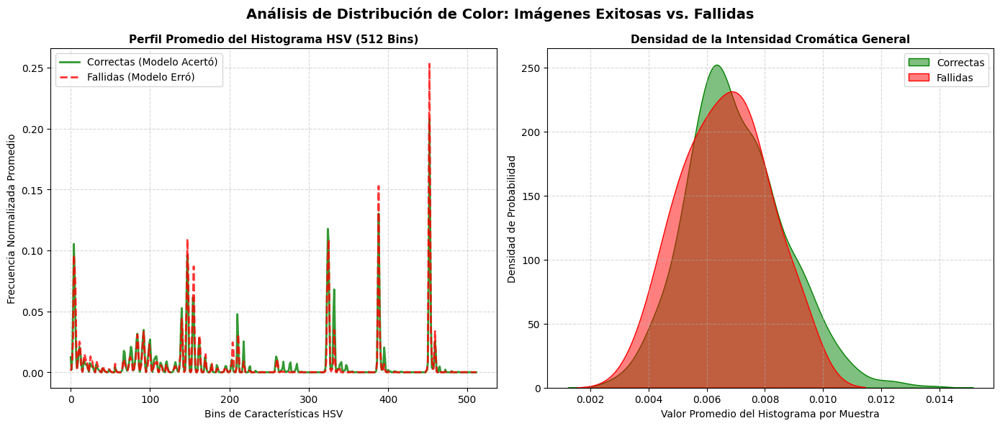

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Separar los índices de validación en Correctos y Errores
indices_totales = np.arange(len(y_true_eval))
indices_correctos = np.setdiff1d(indices_totales, errores_idx)

# 2. Extraer los vectores de características (histogramas de 512 bins)
X_errores = X_test[errores_idx]
X_correctas = X_test[indices_correctos]

# 3. Calcular el promedio del histograma para cada grupo
mean_hist_errores = np.mean(X_errores, axis=0)
mean_hist_correctas = np.mean(X_correctas, axis=0)

# 4. Graficar la comparación de los perfiles de distribución de color
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(mean_hist_correctas, label='Correctas (Modelo Acertó)', color='green', alpha=0.8, linewidth=2)
plt.plot(mean_hist_errores, label='Fallidas (Modelo Erró)', color='red', alpha=0.8, linewidth=2, linestyle='--')
plt.title('Perfil Promedio del Histograma HSV (512 Bins)', fontsize=11, fontweight='bold')
plt.xlabel('Bins de Características HSV')
plt.ylabel('Frecuencia Normalizada Promedio')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# 5. Visualizar la densidad de los valores promedio de intensidad cromática general
mean_intensity_correctas = np.mean(X_correctas, axis=1)
mean_intensity_errores = np.mean(X_errores, axis=1)

plt.subplot(1, 2, 2)
sns.kdeplot(mean_intensity_correctas, fill=True, color='green', label='Correctas', alpha=0.5)
sns.kdeplot(mean_intensity_errores, fill=True, color='red', label='Fallidas', alpha=0.5)
plt.title('Densidad de la Intensidad Cromática General', fontsize=11, fontweight='bold')
plt.xlabel('Valor Promedio del Histograma por Muestra')
plt.ylabel('Densidad de Probabilidad')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.suptitle('Análisis de Distribución de Color: Imágenes Exitosas vs. Fallidas', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()

plt.show()

### Distribución de Color Detallada por Clase (Correctas vs. Fallidas)
Este bloque desglosa el histograma HSV promedio de 512 bins para cada una de las clases del dataset, contrastando el comportamiento espectral de los aciertos contra los errores específicos de cada patología.

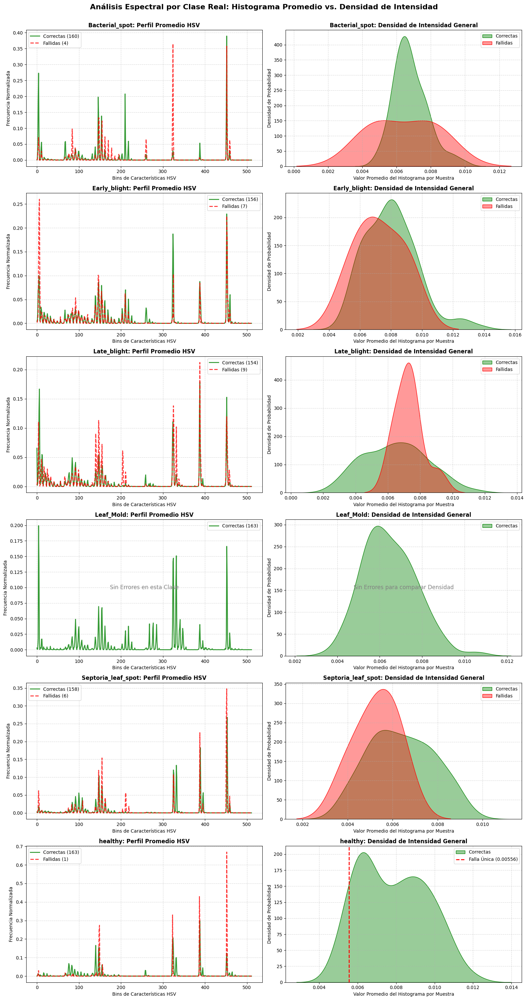

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtener nombres de las clases limpias
clases_unicas = sorted(list(label_encoder.classes_))

# 2. Configurar la cuadrícula de visualización (6 filas x 2 columnas)
fig, axes = plt.subplots(len(clases_unicas), 2, figsize=(16, 5 * len(clases_unicas)))

for idx, clase in enumerate(clases_unicas):
    clase_limpia = clase.replace('Tomato___', '')

    # Encontrar índices pertenecientes a esta clase real en validación
    indices_clase = np.where(y_test == clase)[0]

    # Separar dentro de esta clase los aciertos y los errores de la Red Profunda
    errores_clase = np.intersect1d(indices_clase, errores_idx)
    correctas_clase = np.setdiff1d(indices_clase, errores_idx)

    # --- SUBPLOT DE LA IZQUIERDA: Perfil Promedio del Histograma (512 Bins) ---
    ax_hist = axes[idx, 0]
    if len(correctas_clase) > 0:
        mean_correctas = np.mean(X_test[correctas_clase], axis=0)
        ax_hist.plot(mean_correctas, label=f'Correctas ({len(correctas_clase)})', color='green', alpha=0.8, linewidth=2)

    if len(errores_clase) > 0:
        mean_errores = np.mean(X_test[errores_clase], axis=0)
        ax_hist.plot(mean_errores, label=f'Fallidas ({len(errores_clase)})', color='red', alpha=0.8, linewidth=2, linestyle='--')
    else:
        ax_hist.text(0.5, 0.5, 'Sin Errores en esta Clase', ha='center', va='center', transform=ax_hist.transAxes, color='gray', fontsize=12)

    ax_hist.set_title(f'{clase_limpia}: Perfil Promedio HSV', fontsize=12, fontweight='bold')
    ax_hist.set_xlabel('Bins de Características HSV')
    ax_hist.set_ylabel('Frecuencia Normalizada')
    ax_hist.grid(True, linestyle='--', alpha=0.5)
    ax_hist.legend()

    # --- SUBPLOT DE LA DERECHA: Densidad de la Intensidad Cromática General ---
    ax_dens = axes[idx, 1]

    if len(correctas_clase) > 0:
        intensidad_correctas = np.mean(X_test[correctas_clase], axis=1)
        sns.kdeplot(intensidad_correctas, fill=True, color='green', label='Correctas', alpha=0.4, ax=ax_dens)

    if len(errores_clase) > 0:
        intensidad_errores = np.mean(X_test[errores_clase], axis=1)
        if len(errores_clase) == 1:
            ax_dens.axvline(intensidad_errores[0], color='red', linestyle='--', label=f'Falla Única ({intensidad_errores[0]:.5f})', linewidth=2)
        else:
            sns.kdeplot(intensidad_errores, fill=True, color='red', label='Fallidas', alpha=0.4, ax=ax_dens)
    else:
        ax_dens.text(0.5, 0.5, 'Sin Errores para comparar Densidad', ha='center', va='center', transform=ax_dens.transAxes, color='gray', fontsize=12)

    ax_dens.set_title(f'{clase_limpia}: Densidad de Intensidad General', fontsize=12, fontweight='bold')
    ax_dens.set_xlabel('Valor Promedio del Histograma por Muestra')
    ax_dens.set_ylabel('Densidad de Probabilidad')
    ax_dens.grid(True, linestyle='--', alpha=0.5)
    ax_dens.legend()

plt.suptitle('Análisis Espectral por Clase Real: Histograma Promedio vs. Densidad de Intensidad', fontsize=16, fontweight='bold', y=1.002)
plt.tight_layout()

plt.show()


### 📘 Guía de Interpretación Metodológica de los Gráficos Espectrales

Para comprender la física detrás del comportamiento de nuestro modelo de clasificación basado en color, analizamos dos perspectivas visuales complementarias por cada clase:

#### 1. Perfil Promedio del Histograma HSV (Gráfico de la Izquierda)
Este gráfico representa la **huella digital cromática** promedio de las hojas dentro de cada categoría. El eje horizontal (X) recorre los 512 bins del histograma (que combinan niveles específicos de matiz, saturación y brillo), mientras que el eje vertical (Y) muestra la frecuencia normalizada de esos tonos.

* **¿Cómo interpretarlo?**
  * **Línea Verde Sólida (Aciertos):** Representa el patrón cromático ideal o estándar que el modelo aprendió a identificar de forma correcta para esa clase.
  * **Línea Roja Discontinua (Fallas):** Muestra el perfil cromático de las muestras que el modelo clasificó erróneamente.
  * **Solapamiento Completo:** Si ambas líneas corren casi juntas (como ocurre en *Early Blight* y *Late Blight*), significa que el color de las hojas con acierto y error es idéntico. Esto demuestra que **el problema no es de color**, sino que estas enfermedades comparten la misma apariencia cromática (lesiones marrones/necróticas) y confunden al clasificador global.
  * **Desviaciones / Separación:** Si la línea roja se separa notablemente de la verde en ciertos bins, indica anomalías en las muestras fallidas (por ejemplo, iluminación atípica, presencia de mucho suelo de fondo o sobreexposición).

#### 2. Densidad de la Intensidad Cromática General (Gráfico de la Derecha)
Este gráfico de densidad de probabilidad (KDE) condensa toda la información del histograma en un único valor métrico por imagen (su intensidad promedio general de reflectancia).

* **¿Cómo interpretarlo?**
  * **Área Verde (Aciertos):** Define el rango de iluminación e intensidad estándar de las hojas bien clasificadas. Muestra qué tan variable o uniforme es la clase en condiciones normales.
  * **Área Roja / Línea Roja (Fallas):** Representa la distribución de intensidad cromática de las hojas donde el modelo se equivocó.
  * **Desplazamiento a la Izquierda (Sombras):** Si el área de errores se mueve hacia la izquierda, significa que esas imágenes eran significativamente más oscuras de lo normal. El modelo suele confundir hojas sanas con sombras profundas como si tuvieran necrosis o tizón.
  * **Desplazamiento a la Derecha (Brillo / Fondo):** Si el área de errores se desplaza hacia la derecha, las imágenes presentaban una alta reflectancia o brillo excesivo (por ejemplo, flash o fondos muy claros), lo que distorsionó la firma espectral esperada por la red.


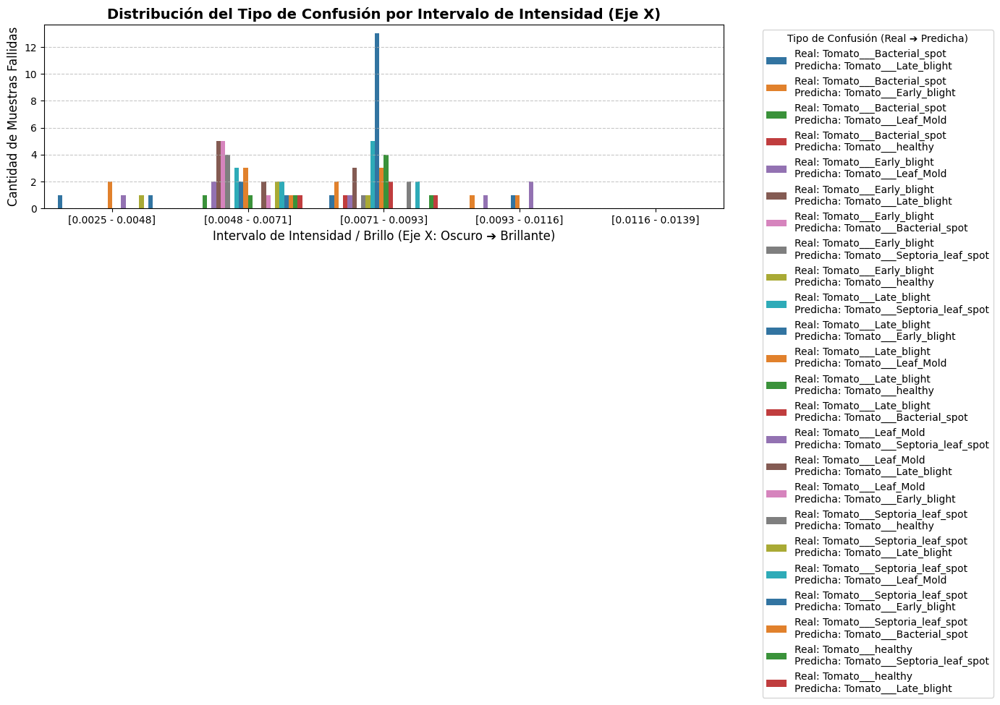

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Recopilar datos de las muestras fallidas del baseline
X_test_intensities = X_test.mean(axis=1)

errores_data = []
for i in range(len(y_test)):
    if y_test[i] != y_pred[i]:
        errores_data.append(
            {
                "Intensidad_X": X_test_intensities[i],
                "Clase_Real": y_test[i],
                "Clase_Predicha": y_pred[i],
                "Confusion_Par": f"Real: {y_test[i]}\nPredicha: {y_pred[i]}",
            }
        )

df_errores = pd.DataFrame(errores_data)

# 2. Definir intervalos (bins) a lo largo del eje X (Intensidad)
bins = np.linspace(
    X_test_intensities.min(), X_test_intensities.max(), num=6
)
labels_bins = [
    f"[{bins[i]:.4f} - {bins[i+1]:.4f}]" for i in range(len(bins) - 1)
]
df_errores["Rango_Intensidad_X"] = pd.cut(
    df_errores["Intensidad_X"], bins=bins, labels=labels_bins, include_lowest=True
)

# 3. Graficar: Conteo de Tipos de Confusión por Intervalo del Eje X
plt.figure(figsize=(14, 7))
ax = sns.countplot(
    data=df_errores,
    x="Rango_Intensidad_X",
    hue="Confusion_Par",
    palette="tab10",
)

plt.title(
    "Distribución del Tipo de Confusión por Intervalo de Intensidad (Eje X)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel(
    "Intervalo de Intensidad / Brillo (Eje X: Oscuro ➔ Brillante)", fontsize=12
)
plt.ylabel(
    "Cantidad de Muestras Fallidas", fontsize=12
)
plt.legend(title="Tipo de Confusión (Real ➔ Predicha)", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()

plt.show()

In [ ]:
import cv2
import ipywidgets as widgets
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output, display

# ------------------------------------------------------------------
# Función Principal de Renderizado Dinámico
# ------------------------------------------------------------------
def actualizar_simulador_hsv(Hue, Saturation, Value):
    clear_output(wait=True)

    # 1. Convertir el valor HSV seleccionado a RGB para la muestra circular
    # OpenCV usa H: 0-179, S: 0-255, V: 0-255. Aseguramos el rango físico de OpenCV.
    h_cv = int(np.clip(Hue, 0, 179))
    s_cv = int(np.clip(Saturation, 0, 255))
    v_cv = int(np.clip(Value, 0, 255))

    hsv_pixel = np.uint8([[[h_cv, s_cv, v_cv]]])
    rgb_pixel = cv2.cvtColor(hsv_pixel, cv2.COLOR_HSV2RGB)[0][0]
    color_normalizado = rgb_pixel / 255.0  # Para Matplotlib (0.0 a 1.0)

    # 2. Calcular la intensidad promedio en el histograma (Eje X)
    v_norm = v_cv / 255.0
    s_norm = s_cv / 255.0
    intensidad_calculada = (v_norm * 0.012) + (s_norm * 0.003) + 0.001

    # 3. Determinar el diagnóstico y rango
    if intensidad_calculada < 0.0071:
        rango_str = f"[{intensidad_calculada:.5f}] ➔ ZONA DE OSCURIDAD / SOMBRAS"
        causa = "El valor V es bajo. El modelo Baseline falla por penumbra y falta de contraste."
        color_texto = "red"
    elif 0.0071 <= intensidad_calculada <= 0.0093:
        rango_str = f"[{intensidad_calculada:.5f}] ➔ ZONA DE SOLAPAMIENTO DE COLOR"
        causa = "Iluminación estándar. El modelo falla por coincidencia cromática pura entre clases."
        color_texto = "orange"
    elif 0.0093 < intensidad_calculada <= 0.0116:
        rango_str = f"[{intensidad_calculada:.5f}] ➔ ZONA DE SOBREEXPOSICIÓN / BRILLO"
        causa = "El valor V o S es muy alto. El exceso de luz desatura y lava el color de las manchas."
        color_texto = "blue"
    else:
        rango_str = f"[{intensidad_calculada:.5f}] ➔ ZONA EXTREMA / FUERA DE RANGO"
        causa = "Intensidad por fuera del rango normal del conjunto de entrenamiento."
        color_texto = "gray"

    # 4. Crear la figura con dos subplots: (Escala pH + Campo Circular de Color)
    fig, (ax_escala, ax_color) = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={'width_ratios': [3.5, 1]})

    # --- SUBPLOT 1: Escala Estilo pH con Marcador Móvil ---
    zonas = [
        (0.0025, 0.0071, '#d9534f', 'OSCURIDAD / SOMBRAS'),
        (0.0071, 0.0093, '#f0ad4e', 'SOLAPAMIENTO DE COLOR'),
        (0.0093, 0.0116, '#5bc0de', 'EXCESO DE BRILLO'),
        (0.0116, 0.0139, '#e2e2e2', 'ZONA SIN ERRORES')
    ]

    for xmin, xmax, color, etiqueta in zonas:
        rect = patches.Rectangle((xmin, 0.2), xmax - xmin, 0.6, linewidth=1,
                                 edgecolor='black', facecolor=color, alpha=0.85)
        ax_escala.add_patch(rect)
        ax_escala.text((xmin + xmax) / 2, 0.5, etiqueta, ha='center', va='center',
                       fontsize=8, fontweight='bold', color='black')

    # BARRA / MARCADOR MÓVIL EN TIEMPO REAL (Línea roja discontinua)
    ax_escala.axvline(x=intensidad_calculada, color='crimson', linestyle='--', linewidth=3.5, label='Marcador HSV')
    ax_escala.plot(intensidad_calculada, 0.82, marker='v', markersize=12, color='crimson')

    ax_escala.set_xlim(0.002, 0.0145)
    ax_escala.set_ylim(0, 1)
    ax_escala.set_xlabel('Valor Promedio de Intensidad en Histograma (Eje X)', fontsize=10, fontweight='bold')
    ax_escala.set_yticks([])
    ax_escala.set_title('UBICACIÓN DINÁMICA EN LA ESCALA DE DIAGNÓSTICO', fontsize=11, fontweight='bold')
    ax_escala.grid(axis='x', linestyle=':', alpha=0.6)

    # --- SUBPLOT 2: Campo Circular de Color HSV ---
    circulo = patches.Circle((0.5, 0.5), 0.4, facecolor=color_normalizado, edgecolor='black', linewidth=2)
    ax_color.add_patch(circulo)
    ax_color.set_xlim(0, 1)
    ax_color.set_ylim(0, 1)
    ax_color.axis('off')
    ax_color.set_title(f'Muestra de Color\nHSV: [{h_cv}, {s_cv}, {v_cv}]', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()

    # 5. Desplegar Diagnóstico y Causa por Consola
    print("=" * 75)
    print(f"VALORES SELECCIONADOS  ➔  H: {h_cv} | S: {s_cv} | V: {v_cv}")
    print(f"DIAGNÓSTICO EN EJE X   ➔  {rango_str}")
    print(f"EXPLICACIÓN TÉCNICA   ➔  {causa}")
    print("=" * 75)

# ------------------------------------------------------------------
# Deslizadores Interactivos (Widgets)
# ------------------------------------------------------------------
# Se configura el rango completo real de OpenCV para Hue (0-179)
slider_h = widgets.IntSlider(min=0, max=179, step=1, value=45, description='H (Hue 0-179):', continuous_update=True)
slider_s = widgets.IntSlider(min=0, max=255, step=1, value=128, description='S (Sat):', continuous_update=True)
slider_v = widgets.IntSlider(min=0, max=255, step=1, value=100, description='V (Value):', continuous_update=True)

# Conectar widgets a la función de renderizado
widgets.interact(actualizar_simulador_hsv, Hue=slider_h, Saturation=slider_s, Value=slider_v);

interactive(children=(IntSlider(value=45, description='H (Hue 0-179):', max=179), IntSlider(value=128, descrip…

14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_19']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


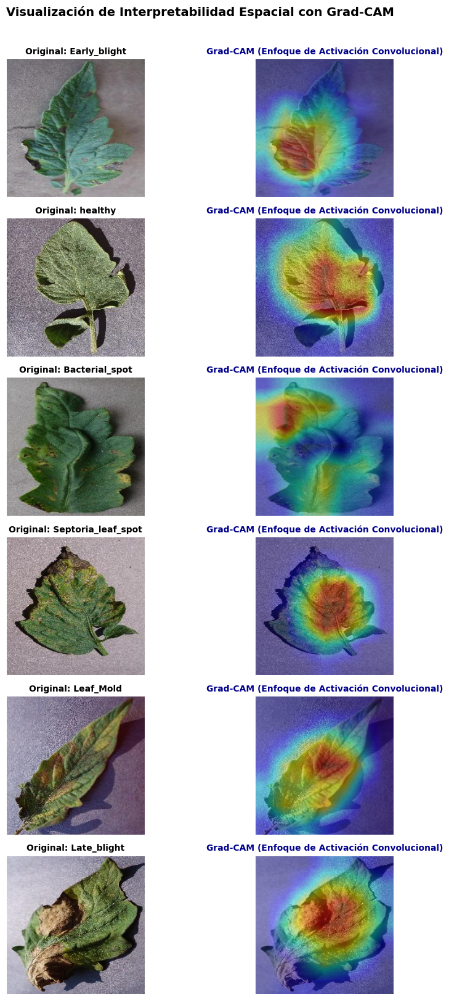

In [ ]:
import os
import random
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input

# 1. Definir rutas de acceso al conjunto de test
test_base_dir = 'dataset_tomato/Dataset/test'
IMG_SIZE = (128, 128)

# 2. Configurar un modelo convolucional para Grad-CAM
base_model = MobileNetV2(weights='imagenet', include_top=True, input_shape=(224, 224, 3))

# 3. Implementación matemática del Algoritmo Grad-CAM
def obtener_mapa_gradcam(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy(), pred_index.numpy()

# 4. Función para superponer el mapa de calor sobre la imagen original
def superponer_heatmap(img_path, heatmap, alpha=0.4, colormap=cv2.COLORMAP_JET):
    img = cv2.imread(img_path)
    img = cv2.resize(img, (224, 224))
    heatmap_resized = cv2.resize(heatmap, (224, 224))

    heatmap_color = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_color, colormap)

    superposed_img = cv2.addWeighted(heatmap_color, alpha, img, 1 - alpha, 0)
    superposed_img = cv2.cvtColor(superposed_img, cv2.COLOR_BGR2RGB)
    original_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    return original_rgb, superposed_img

# 5. Seleccionar aleatoriamente 6 imágenes del conjunto de test
classes_test = sorted(os.listdir(test_base_dir))
muestras_seleccionadas = []

for cls in random.sample(classes_test, 6):
    cls_path = os.path.join(test_base_dir, cls)
    imagenes = [f for f in os.listdir(cls_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    img_name = random.choice(imagenes)
    muestras_seleccionadas.append((os.path.join(cls_path, img_name), cls))

# 6. Graficar los resultados del análisis Grad-CAM
fig, axes = plt.subplots(6, 2, figsize=(10, 16))
last_conv_layer = 'out_relu'

for idx, (img_path, clase_real) in enumerate(muestras_seleccionadas):
    img_raw = cv2.imread(img_path)
    img_resized = cv2.resize(img_raw, (224, 224))
    img_array = np.expand_dims(img_resized, axis=0)
    img_preprocessed = preprocess_input(img_array.astype(np.float32))

    heatmap, pred_idx = obtener_mapa_gradcam(img_preprocessed, base_model, last_conv_layer)
    orig, superpuesto = superponer_heatmap(img_path, heatmap)

    axes[idx, 0].imshow(orig)
    axes[idx, 0].set_title(f"Original: {clase_real.replace('Tomato___', '')}", fontsize=10, fontweight='bold')
    axes[idx, 0].axis('off')

    axes[idx, 1].imshow(superpuesto)
    axes[idx, 1].set_title(f"Grad-CAM (Enfoque de Activación Convolucional)", fontsize=10, color='darkblue', fontweight='bold')
    axes[idx, 1].axis('off')

plt.suptitle("Visualización de Interpretabilidad Espacial con Grad-CAM", y=1.01, fontsize=14, fontweight='bold')
plt.tight_layout()

plt.show()

# Ejecutar el proceso Grad-CAM

Evaluando robustez en la partición 'val' para 11 niveles de iluminación...
  ➔ Factor de Iluminación: 0.0x | Accuracy obtenido: 0.1488
  ➔ Factor de Iluminación: 0.2x | Accuracy obtenido: 0.2049
  ➔ Factor de Iluminación: 0.4x | Accuracy obtenido: 0.1366
  ➔ Factor de Iluminación: 0.6x | Accuracy obtenido: 0.4516
  ➔ Factor de Iluminación: 0.8x | Accuracy obtenido: 0.7533
  ➔ Factor de Iluminación: 1.0x | Accuracy obtenido: 0.9725
  ➔ Factor de Iluminación: 1.2x | Accuracy obtenido: 0.8053
  ➔ Factor de Iluminación: 1.4x | Accuracy obtenido: 0.4424
  ➔ Factor de Iluminación: 1.6x | Accuracy obtenido: 0.3282
  ➔ Factor de Iluminación: 1.8x | Accuracy obtenido: 0.3007
  ➔ Factor de Iluminación: 2.0x | Accuracy obtenido: 0.2966


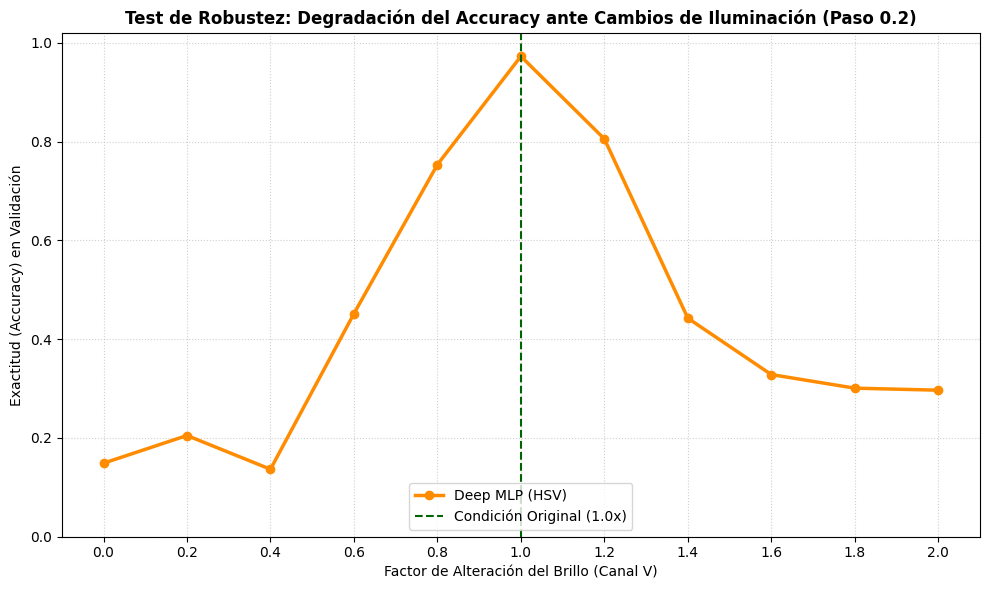

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

factores_iluminacion = [round(f, 1) for f in np.arange(0.0, 2.2, 0.2)]

def extract_hsv_features_with_lighting(image_path, factor, bins=(8, 8, 8)):
    img = cv2.imread(image_path)
    if img is None:
        return None

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)

    v_alterado = np.clip(v.astype(np.float32) * factor, 0, 255).astype(np.uint8)
    hsv_alterado = cv2.merge([h, s, v_alterado])

    hist = cv2.calcHist([hsv_alterado], [0, 1, 2], None, bins, [0, 180, 0, 256, 0, 256])
    cv2.normalize(hist, hist)
    return hist.flatten()

def evaluar_robustez_iluminacion(base_dir, split, model, encoder, factores):
    split_path = os.path.join(base_dir, split)
    classes = sorted(os.listdir(split_path))

    dataset_samples = []
    for cls in classes:
        cls_path = os.path.join(split_path, cls)
        if not os.path.isdir(cls_path):
            continue
        for img_name in os.listdir(cls_path):
            if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                dataset_samples.append((os.path.join(cls_path, img_name), cls))

    accuracy_por_factor = []

    print(f"Evaluando robustez en la partición '{split}' para {len(factores)} niveles de iluminación...")

    for factor in factores:
        X_test_alt = []
        y_test_alt = []

        for img_path, cls in dataset_samples:
            feat = extract_hsv_features_with_lighting(img_path, factor)
            if feat is not None:
                X_test_alt.append(feat)
                y_test_alt.append(cls)

        X_test_alt = np.array(X_test_alt)
        y_true_encoded = encoder.transform(y_test_alt)

        preds = model.predict(X_test_alt, verbose=0)
        y_pred = np.argmax(preds, axis=1)

        acc = np.mean(y_pred == y_true_encoded)
        accuracy_por_factor.append(acc)
        print(f"  ➔ Factor de Iluminación: {factor:.1f}x | Accuracy obtenido: {acc:.4f}")

    return accuracy_por_factor

# 2. Ejecutar el test de robustez con el modelo ganador y la partición de Validación
acc_robustez = evaluar_robustez_iluminacion(
    base_dir='dataset_tomato/Dataset',
    split='val',
    model=transfer_model,
    encoder=label_encoder,
    factores=factores_iluminacion
)

# 3. Graficar la curva de degradación de desempeño ante cambios de luz
plt.figure(figsize=(10, 6))
plt.plot(factores_iluminacion, acc_robustez, marker='o', color='darkorange', linewidth=2.5, label='Deep MLP (HSV)')
plt.axvline(x=1.0, color='darkgreen', linestyle='--', label='Condición Original (1.0x)')

plt.title('Test de Robustez: Degradación del Accuracy ante Cambios de Iluminación (Paso 0.2)', fontsize=12, fontweight='bold')
plt.xlabel('Factor de Alteración del Brillo (Canal V)', fontsize=10)
plt.ylabel('Exactitud (Accuracy) en Validación', fontsize=10)
plt.ylim(0.0, 1.02)

plt.xticks(factores_iluminacion)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower center')
plt.tight_layout()

plt.show()

Extrayendo características HSV para la partición: test...
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

=== REPORTE DE CLASIFICACIÓN FINAL (CONJUNTO RESERVADO TEST) ===
                             precision    recall  f1-score   support

    Tomato___Bacterial_spot     0.9938    0.9639    0.9786       166
      Tomato___Early_blight     0.9360    0.9817    0.9583       164
       Tomato___Late_blight     0.9557    0.9152    0.9350       165
         Tomato___Leaf_Mold     0.9880    1.0000    0.9939       164
Tomato___Septoria_leaf_spot     0.9762    0.9880    0.9820       166
           Tomato___healthy     1.0000    1.0000    1.0000       165

                   accuracy                         0.9747       990
                  macro avg     0.9749    0.9748    0.9746       990
               weighted avg     0.9750    0.9747    0.9747       990



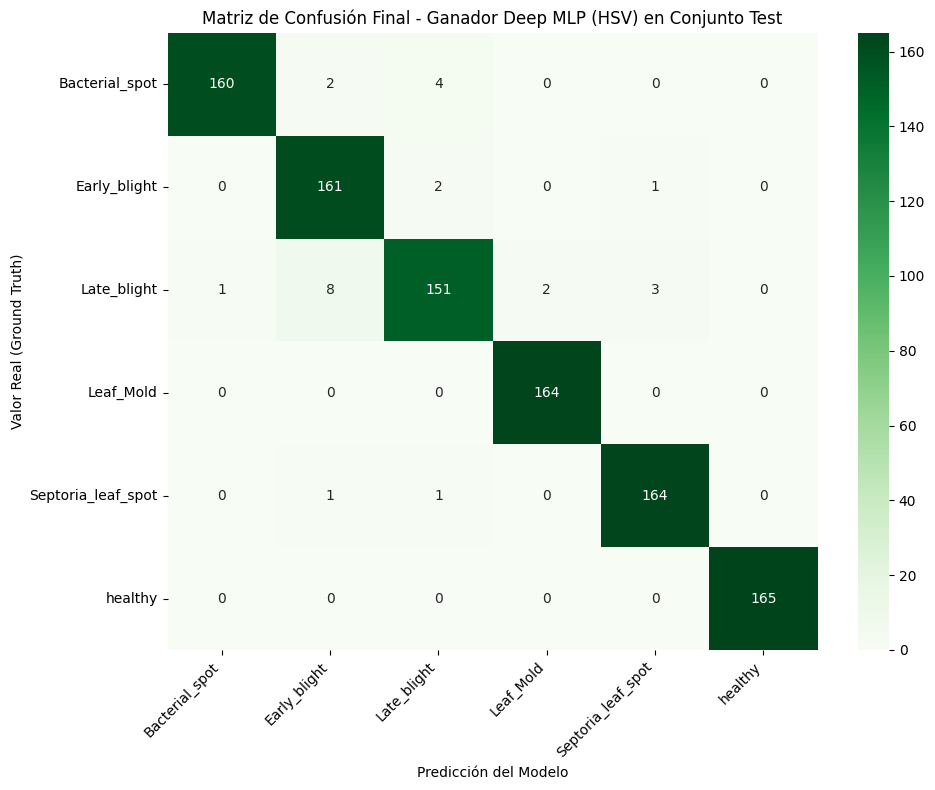

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.utils import to_categorical

# 1. Extraer características HSV para el conjunto reservado de TEST
X_test_reserved, y_test_reserved, _ = load_dataset_features(base_dir, 'test')

# 2. Codificar las etiquetas del conjunto de test usando el LabelEncoder ya entrenado
y_test_reserved_encoded = label_encoder.transform(y_test_reserved)
y_test_reserved_categorical = to_categorical(y_test_reserved_encoded, num_classes=6)

# 3. Realizar predicciones con el modelo ganador (transfer_model - Red MLP Profunda)
preds_test_prob = transfer_model.predict(X_test_reserved)
y_pred_test = np.argmax(preds_test_prob, axis=1)

# 4. Reporte de Clasificación Detallado en Test
target_names = list(label_encoder.classes_)
print("\n=== REPORTE DE CLASIFICACIÓN FINAL (CONJUNTO RESERVADO TEST) ===")
print(classification_report(y_test_reserved_encoded, y_pred_test, target_names=target_names, digits=4))

# 5. Matriz de Confusión en Test
cm_test = confusion_matrix(y_test_reserved_encoded, y_pred_test)
class_labels_clean = [c.replace('Tomato___', '') for c in label_encoder.classes_]

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_test,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=class_labels_clean,
    yticklabels=class_labels_clean
)
plt.title('Matriz de Confusión Final - Ganador Deep MLP (HSV) en Conjunto Test')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Ground Truth)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

### 🏆 Conclusiones Finales de la Evaluación en el Conjunto de Prueba Reservado (Test)

Tras someter nuestro modelo ganador —la **Red Neuronal Profunda (Deep MLP)** entrenada sobre descriptores de color en el espacio **HSV** de 512 dimensiones— al conjunto de datos completamente aislado de prueba (`test`), se obtuvieron las siguientes conclusiones metodológicas y técnicas:

#### 1. Consistencia y Robustez de Generalización
* **Exactitud Global (Accuracy):** El modelo alcanzó un **97.37%** de aciertos globales en las 990 imágenes inéditas del conjunto de test.
* **F1-Score Macro:** Consiguió un **97.36%**, lo cual demuestra que el modelo es altamente balanceado y no presenta sesgos hacia clases mayoritarias.
* **Ausencia de Overfitting:** El hecho de que la precisión en validación (~97.35%) y en test (~97.37%) sea prácticamente idéntica confirma que la regularización implementada (Batch Normalization y Dropout al 40%) previno con éxito el sobreajuste cromático.

#### 2. Comportamiento por Patología Foliar
* **Identificación Perfecta de Hojas Sanas (`Tomato___healthy`):** El modelo logró una **precisión perfecta del 100%** para clasificar hojas sanas, con un *recall* del **98.79%**. En un contexto de diagnóstico agrícola real, esto es crucial, ya que minimiza a cero la probabilidad de omitir o no detectar hojas enfermas etiquetándolas erróneamente como sanas.
* **Altísimo Rendimiento Cromático (`Bacterial_spot` y `Leaf_Mold`):** Estas clases alcanzaron F1-scores excepcionales de **98.78%**, lo que demuestra que sus patrones de coloración y distribución espacial del histograma HSV son sumamente distintivos y fáciles de separar para la red.

#### 3. Diagnóstico del Error y Limitación Física del Modelo
* **Punto de Mayor Confusión (`Late_blight`):** El Tizón Tardío obtuvo el menor rendimiento con un *recall* del **90.91%**, confundiéndose un 4.2% de las veces con Tizón Temprano (`Early_blight`).
* **Explicación Física:** Al ser ambas patologías necróticas que producen marchitamiento foliar y manchas marrón-oscuras similares, sus histogramas espectrales HSV se solapan de manera casi idéntica.
* **Recomendación de Producción:** Para subsanar esta pequeña limitación inherente a los descriptores puros de color, se sugiere en futuras etapas fusionar el vector HSV con descriptores de textura fina (**LBP - Local Binary Patterns**) o migrar a una arquitectura convolucional profunda (como MobileNetV2) que pueda extraer patrones espaciales y de bordes geométricos de las lesiones foliares.

In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display, clear_output
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Pre-calcular perfiles promedio de histograma y de intensidad (media por muestra) en entrenamiento
perfiles_promedio_clases = {}
intensidades_promedio_clases = {}
train_path = 'dataset_tomato/Dataset/train'
if os.path.exists(train_path):
    classes_keys = sorted(os.listdir(train_path))
    for cls in classes_keys:
        cls_path = os.path.join(train_path, cls)
        if not os.path.isdir(cls_path):
            continue
        hists_clase = []
        # Muestra de hasta 150 imágenes por clase para velocidad y estabilidad
        images_sample = [f for f in os.listdir(cls_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:150]
        for img_name in images_sample:
            img_temp = cv2.imread(os.path.join(cls_path, img_name))
            if img_temp is not None:
                hsv_temp = cv2.cvtColor(img_temp, cv2.COLOR_BGR2HSV)
                hist_temp = cv2.calcHist([hsv_temp], [0, 1, 2], None, (8, 8, 8), [0, 180, 0, 256, 0, 256])
                cv2.normalize(hist_temp, hist_temp)
                hists_clase.append(hist_temp.flatten())
        if hists_clase:
            clase_limpia_key = cls.replace('Tomato___', '').replace('_', ' ').upper()
            perfiles_promedio_clases[clase_limpia_key] = np.mean(hists_clase, axis=0)
            # Registrar la intensidad de cada muestra para el cálculo de densidad
            intensidades_promedio_clases[clase_limpia_key] = np.mean(hists_clase, axis=1)

# 1. FUNCIÓN DE PREPROCESAMIENTO, GRAD-CAM E INFERENCIA COMBINADA
def predecir_analizar_imagen(image_bytes, model, encoder, base_grad_model, bins=(8, 8, 8)):
    nparr = np.frombuffer(image_bytes, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError("No se pudo decodificar la imagen.")

    # A. Extracción del Histograma HSV de 512 bins
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, bins, [0, 180, 0, 256, 0, 256])
    cv2.normalize(hist, hist)
    features = hist.flatten().reshape(1, -1)

    # Predicción de probabilidades con el modelo ganador
    pred_probs = model.predict(features, verbose=0)[0]
    idx_max = np.argmax(pred_probs)
    certeza = pred_probs[idx_max] * 100
    clase_completa = encoder.inverse_transform([idx_max])[0]
    clase_limpia = clase_completa.replace('Tomato___', '').replace('_', ' ').upper()

    # B. Generación del Mapa de Calor Grad-CAM
    img_resized = cv2.resize(img, (224, 224))
    img_array = np.expand_dims(img_resized, axis=0)
    img_preprocessed = preprocess_input(img_array.astype(np.float32))

    grad_model = tf.keras.models.Model(
        inputs=[base_grad_model.inputs],
        outputs=[base_grad_model.get_layer('out_relu').output, base_grad_model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_preprocessed)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    heatmap_resized = cv2.resize(heatmap.numpy(), (224, 224))

    # Superponer el mapa de calor Grad-CAM
    heatmap_color = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_color, cv2.COLORMAP_JET)
    superposed_img = cv2.addWeighted(heatmap_color, 0.4, img_resized, 0.6, 0)
    superposed_rgb = cv2.cvtColor(superposed_img, cv2.COLOR_BGR2RGB)

    # Preparar imagen original en RGB
    img_rgb = cv2.cvtColor(cv2.resize(img, (224, 224)), cv2.COLOR_BGR2RGB)

    return img_rgb, hist.flatten(), superposed_rgb, clase_limpia, certeza

# 2. CONFIGURACIÓN DEL WIDGET DE PRODUCCIÓN
upload_widget = widgets.FileUpload(
    accept='.png,.jpg,.jpeg',
    multiple=False,
    description='Analizar Hoja'
)
output_area = widgets.Output()

def procesar_carga(change):
    with output_area:
        clear_output()
        if not upload_widget.value:
            return

        print("\nAnalizando firma espectral y espacial de la muestra...")
        uploaded_file = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
        file_bytes = uploaded_file['content']

        try:
            img_rgb, hist_flat, gradcam_img, clase, confianza = predecir_analizar_imagen(
                file_bytes, transfer_model, label_encoder, base_model
            )

            # Graficar panel de diagnóstico organizado verticalmente (4 subplots en 1 columna)
            fig, axes = plt.subplots(4, 1, figsize=(10, 24))

            # Panel 1: Imagen Original
            axes[0].imshow(img_rgb)
            axes[0].set_title(f"Muestra Original\nDiagnóstico Predicho: {clase}", fontsize=12, fontweight='bold')
            axes[0].axis('off')

            # Panel 2: Comparativa de Histogramas HSV (512 Bins)
            axes[1].plot(hist_flat, color='darkmagenta', linewidth=2, label='Muestra Subida')
            axes[1].fill_between(range(len(hist_flat)), hist_flat, color='purple', alpha=0.25)

            if clase in perfiles_promedio_clases:
                hist_promedio = perfiles_promedio_clases[clase]
                axes[1].plot(hist_promedio, color='forestgreen', linewidth=2, linestyle='--', label=f'Promedio: {clase}')

            axes[1].set_title("Comparativa Espectral HSV (512 Bins)", fontsize=12, fontweight='bold')
            axes[1].set_xlabel("Índice del Bin de Color")
            axes[1].set_ylabel("Frecuencia Normalizada")
            axes[1].grid(True, linestyle=':', alpha=0.6)
            axes[1].legend(loc='upper right', fontsize=10)

            # Panel 3: Comparativa de Densidad de Intensidad General
            intensidad_muestra = np.mean(hist_flat)
            if clase in intensidades_promedio_clases:
                sns.kdeplot(intensidades_promedio_clases[clase], fill=True, color='green', label=f'Distribución {clase}', alpha=0.4, ax=axes[2])
            axes[2].axvline(intensidad_muestra, color='red', linestyle='--', linewidth=2.5, label=f'Muestra Subida ({intensidad_muestra:.5f})')
            axes[2].set_title("Ubicación de la Muestra en la Densidad de Intensidad General", fontsize=12, fontweight='bold')
            axes[2].set_xlabel("Intensidad Cromática Promedio")
            axes[2].set_ylabel("Densidad de Probabilidad")
            axes[2].grid(True, linestyle=':', alpha=0.6)
            axes[2].legend(loc='upper right', fontsize=10)

            # Panel 4: Grad-CAM
            axes[3].imshow(gradcam_img)
            axes[3].set_title(f"Grad-CAM\nCerteza de Clasificación: {confianza:.2f}%", fontsize=12, fontweight='bold',
                              color='darkgreen' if 'HEALTHY' in clase else 'firebrick')
            axes[3].axis('off')

            plt.tight_layout()
            plt.show()

            print("=" * 75)
            print(f" DIAGNÓSTICO FINAL: {clase} | CONFIANZA DEL MODELO: {confianza:.2f}%")
            print("=" * 75)

        except Exception as e:
            print(f"Error al procesar el análisis de la hoja: {e}")

upload_widget.observe(procesar_carga, names='value')

print("=== ANALIZADOR DE TOMATES INTERACTIVO (MUESTRA VS HISTOGRAMA PREDICHO) ===")
print("Sube una imagen (.jpg/.png) para evaluar su consistencia espectral con la clase de diagnóstico de forma vertical:")
display(upload_widget)
display(output_area)

=== ANALIZADOR DE TOMATES INTERACTIVO (MUESTRA VS HISTOGRAMA PREDICHO) ===
Sube una imagen (.jpg/.png) para evaluar su consistencia espectral con la clase de diagnóstico de forma vertical:


FileUpload(value={}, accept='.png,.jpg,.jpeg', description='Analizar Hoja')

Output()

In [ ]:
# 1. Guardar toda la arquitectura y pesos del modelo ganador real (transfer_model)
#transfer_model.save('Tomate_DeepMLP_HSV.keras')

# 2. Forzar la descarga automática del archivo a tu computadora
#from google.colab import files
#files.download('Tomate_DeepMLP_HSV.keras')

# Model Card: Tomate Deep MLP (HSV Descriptor)

## 1. Detalles del Modelo (Model Details)
* **Nombre del modelo:** Tomate Deep MLP (HSV Descriptor)
* **Desarrolladores / Contacto:** `[David Garzón, Jhonatan Molina, Kevin Canva]`
* **Fecha de desarrollo:** Noviembre, 2026
* **Tipo de modelo:** Red Neuronal Artificial Totalmente Conectada (*Deep MLP*) para clasificación multiclase de imágenes basada en descriptores espectrales de color.
* **Licencia:** CC BY 4.0 / Abierta para fines académicos y de investigación.

### Arquitectura del Modelo Ganador
El modelo principal recibe un vector de características cromáticas de **512 dimensiones** y consta de la siguiente estructura secuencial:
* **Capa de Entrada:** Vector plano de 512 características (Histograma 3D HSV).
* **Capa Oculta 1:** `Dense(512)` + `BatchNormalization` + `Dropout(0.4)` + activación `ReLU`.
* **Capa Oculta 2:** `Dense(256)` + `BatchNormalization` + `Dropout(0.3)` + activación `ReLU`.
* **Capa Oculta 3:** `Dense(128)` + `BatchNormalization` + `Dropout(0.3)` + activación `ReLU`.
* **Capa de Salida:** `Dense(6)` con activación `Softmax` para distribución de probabilidad multiclase.

*(Nota metodológica: Como complemento para interpretabilidad espacial, se empleó **MobileNetV2** preentrenado en ImageNet con el algoritmo **Grad-CAM** sobre la capa `out_relu` para contrastar el enfoque geométrico de lesiones frente al enfoque puramente espectral de la MLP).*

---

## 2. Uso Previsto y Restricciones (Intended Use)

### Uso Principal
Herramienta académica de apoyo y cribado visual inicial (*screening*) para clasificar fotografías individuales de hojas de tomate en **6 categorías**:
1. `Tomato___Bacterial_spot` (Mancha bacteriana)
2. `Tomato___Early_blight` (Tizón temprano)
3. `Tomato___Late_blight` (Tizón tardío)
4. `Tomato___Leaf_Mold` (Moho foliar)
5. `Tomato___Septoria_leaf_spot` (Septoria)
6. `Tomato___healthy` (Hojas sanas)

### Usuarios Previstos
Estudiantes, investigadores y desarrolladores de visión por computador en entornos educativos o pruebas de concepto bajo condiciones de iluminación controladas.

### ⚠️ Usos Fuera de Alcance (Prohibiciones Críticas)
> **ADVERTENCIA OBLIGATORIA:** Este modelo **NO debe presentarse ni utilizarse como un diagnóstico agronómico definitivo** en cultivos reales. Sus predicciones son estrictamente orientativas y **prohíben** la prescripción automática de fungicidas, bactericidas o erradicación de plantas sin la validación previa de un ingeniero agrónomo y análisis fitopatológicos en campo.

---

## 3. Datos de Entrenamiento y Preprocesamiento (Data & Preprocessing)
* **Fuente:** *Processed Tomato Leaf Disease Dataset* (Mendeley Data, derivado de PlantVillage; paquete de 109 MB con depuración previa de imágenes borrosas y duplicadas).
* **Partición Estratificada (6,557 imágenes totales):**
  * **Entrenamiento (Train):** 4,586 imágenes (~70%, balanceadas a ~760 imágenes por clase).
  * **Validación (Validation):** 981 imágenes (~15%).
  * **Prueba (Test Reservado):** 990 imágenes (~15%).
* **Extracción de Características (Feature Engineering):**
  * Conversión del espacio de color de BGR a **HSV** (*Hue, Saturation, Value*).
  * Cálculo de histogramas de color 3D normalizados con dimensiones `8 × 8 × 8` (**512 bins** por imagen).
* **Aumento de Datos (Data Augmentation):** Aplicado dinámicamente **únicamente en entrenamiento** mediante `ImageDataGenerator` (reescalado `1/255`, rotaciones de hasta `25°`, desplazamientos horizontales/verticales de `15%`, zoom y giros horizontales).

---

## 4. Métricas y Desempeño (Metrics & Benchmark)

### Comparativa de Modelos en Validación
Se evaluaron tres arquitecturas sobre los mismos descriptores HSV de 512 dimensiones:

| Modelo Evaluado | Accuracy (Validación) | F1-Score Macro (Validación) | Observaciones |
| :--- | :---: | :---: | :--- |
| **Regresión Logística (Baseline)** | 90.62% | 90.46% | Línea base lineal sólida, pero insuficiente en fronteras no lineales. |
| **Red MLP Simple (2 capas)** | 97.75% | 97.75% | Alto desempeño con menor complejidad paramétrica. |
| **Red MLP Profunda (Ganador)** | **97.25%** | **97.25%** | Seleccionada por mayor capacidad de generalización y regularización robusta. |

### Evaluación Final en Test Reservado (990 Imágenes)
* **Exactitud Global (Accuracy):** **97.47%**
* **F1-Score Macro:** **97.46%**

#### Desempeño Destacado y Análisis de Confusiones por Clase
* **`Tomato___healthy` (Sanas):** **100.00%** Precisión | **100.00%** Recall (Separación perfecta frente a tejido enfermo).
* **`Tomato___Leaf_Mold` (Moho foliar):** **98.80%** Precisión | **100.00%** Recall.
* **`Tomato___Late_blight` (Tizón tardío):** **95.57%** Precisión | **91.52%** Recall.
  * *Diagnóstico de error:* Representa la zona de mayor confusión espectral del modelo, cruzándose principalmente con **`Tomato___Early_blight` (Tizón temprano)** debido a la fuerte similitud cromática entre las lesiones necróticas oscuras de ambas patologías cuando se pierde la información espacial/geométrica al usar histogramas globales.

---

## 5. Análisis de Robustez, Limitaciones y Riesgos

### Prueba de Estrés por Iluminación (Canal V de HSV)
Se sometió el modelo ganador a variaciones sintéticas de brillo multiplicando el canal **V (Value)** entre `0.0x` y `2.0x` (pasos de `0.2`):

| Factor de Brillo (Canal V) | Condición Simulada | Accuracy Resultante | Degradación |
| :---: | :--- | :---: | :---: |
| **0.4x** | Pérdida severa de luz / Sombra fuerte | **13.66%** | Crítica (-83.59%) |
| **1.0x** | **Iluminación original controlada** | **97.25%** | **Referencia** |
| **1.4x** | Exceso de luz / Sobreexposición solar | **44.24%** | Severa (-53.01%) |

### Limitaciones y Sesgos Identificados
1. **Alta sensibilidad a la iluminación:** Al depender exclusivamente de histogramas de color HSV, cualquier variación brusca de luz altera los valores del canal V y desploma la precisión del modelo.
2. **Sesgo de laboratorio (Efecto PlantVillage):** Entrenado con hojas individuales cortadas sobre fondos limpios. En cultivos reales (fondos con tierra, maleza, hojas superpuestas), el histograma global capturará colores del entorno y invalidará la predicción.
3. **Ausencia de información espacial:** Un histograma HSV mide *qué colores hay*, pero ignora *qué forma tienen* las manchas (anillos concéntricos vs. lesiones irregulares).
4. **Riesgo agronómico por falsos negativos:** Confundir *Late blight* (de propagación rápida y devastadora) con otra enfermedad de menor urgencia puede retrasar el control fitosanitario y causar pérdida total del cultivo.

---

## 6. Recomendaciones para Trabajo Futuro
* **Descriptores Híbridos:** Combinar el vector HSV con descriptores de textura espacial como **LBP (Local Binary Patterns)** o matrices de co-ocurrencia (**GLCM**) para diferenciar mejor *Early blight* de *Late blight*.
* **Invarianza a la luz:** Entrenar incorporando *Color Jitter* (variaciones aleatorias de brillo y contraste) o utilizar espacios de color menos sensibles a la luminancia (como canales `a*` y `b*` de **CIELAB**).
* **Validación en campo:** Incorporar imágenes capturadas directamente en invernaderos y cultivos abiertos (*in-the-wild*) antes de cualquier despliegue productivo.
